# Un core · liberación y O₂ · A=0 y theta_nv2 fijos

Se evalúan seis configuraciones: liberación histórica de2.348167954,1.174083977 y0.587041989h⁻¹ (referencia E1 del09, mitad y cuarta parte), con y sin modulación O₂. **No hay optimización.** A=0, theta_nv2, escala de saturación, ganancia, actividad final, rampa y demás parámetros permanecen fijos.

Una sola química nutrida por LAB, reutilizada en todos los escenarios. El consumo de O₂ usa exclusivamente su biomasa X(t); no integra química sin nutrición ni accede a core0. Las curvas químicas son idénticas entre escenarios y no hay realimentación del gas al etanol o azúcares.

Fuente sin O₂: \(q_{\rm prod}=\mathrm{gate}\,a(t)(44.01/46.07)(\beta_G+\beta_F)X\).
Con O₂ se multiplica por \(f_{O₂}=0.08+0.92(0.75)^2/[(0.75)^2+O^2]\).
\[
\dot O=-q_{O₂,\max}X\,O/(0.25+O).
\]
Se conserva la integración explícita histórica sobre la misma malla, limitada a O≥0. Inicial O=O2_initial_scale·saturaciónO₂(T0,E0,G0,F0), con escala0.19539966565 y qmax0.15mg/(g·h). Son supuestos empíricos heredados, no mediciones nuevas. No hay reposición de O₂ por aireación ni pulsos de oxígeno.

El depósito permanece histórico:
\[
\dot C_d=q_{\rm prod}-q_{\rm gas},\qquad
q_{\rm gas}=kC_d[0.05+0.95C_d/(C_d+C_{\rm sat})],\quad q_{\rm medido}=gq_{\rm gas}.
\]
Cd0=0. Csat depende de temperatura, etanol y azúcares con la correlación provisional del09; escala=2.5. No se sustituye por transferencia de Zenteno.

Mediciones: mismas medianas horarias de RAW convertida por volumen remanente, sin filtrar predicciones. Temperaturas de logs procesadas por el lector histórico; condiciones iniciales, nutrientes y cortes iguales al09/10; LAB017 un solo pulso0.28g/L. Los rótulos calibración/holdout indican la procedencia de los parámetros del09, no nuevos ajustes.

Todas las figuras comparan **sólo dos configuraciones y las mediciones**. Primero cada reducción de liberación frente a referencia, sin O₂; después con/sin O₂ a cada liberación. Vistas separadas: registro completo, arranque hasta primer pulso, pico durante24h posteriores y cola desde32h después. Ejes y automáticos desde0. Se imprimen entradas, parámetros, ventanas, máximos, sesgos, áreas y RMSE por LAB; residuo censurado para observación<0.05 además de RMSE ordinario.

A diferencia de bajar k, la modulación O₂ atenúa la fuente: no representa simplemente almacenar ese CO₂ para liberarlo después. Se muestran factor O₂ y Cd por separado. No se seleccionan parámetros a partir del holdout. Sin archivos CSV/PNG de resultados ni modificaciones de modelos, datos, parámetros o notebooks anteriores.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display,Markdown
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation.models.historical import co2 as gas,kinetics
from wine_fermentation.models.historical.calibration import load,release_forward,Search
from wine_fermentation.comparison import observations
NAME='11_single_core_release_O2'
protected=[p for folder in ('src','configs','data','notebooks','results') for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and not p.name.startswith(NAME+'.')]
before={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
old=__import__('nbformat').read(ROOT/'notebooks/diagnostics/09_historical_single_core.executed.ipynb',4)
stream=''.join(o.get('text','') for o in old.cells[4].outputs if o.output_type=='stream')
records=json.JSONDecoder().raw_decode(stream.split('PARAMETROS_COMPLETOS_SIN_EXPORTACION\n')[1])[0]
p0=next(r['parametros'] for r in records if r['caso']=='Propuesta · un core, sin O₂' and r['etapa']=='E1')
assert p0['A']==.3
theta=kinetics.normalize_parameters(json.loads((ROOT/'configs/theta/theta_nv2.json').read_text()))
theta_before=theta.copy();assert 0<theta['Yeg']<=.5114 and 0<theta['Yef']<=.5114
v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018']
batches=dict(v.batches);b=batches['LAB017'];events=b.pulses['N'];assert np.isclose(sum(d for t,d in events),.28)
batches['LAB017']=replace(b,pulses={**b.pulses,'N':((min(t for t,d in events),.28),)})
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','co2_raw_g_l_h'])
obs=observations(raw);support={lab:obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy() for lab in LABS}
contexts={};calls=0
for lab,b in batches.items():
 f=gas.integrate_core(b,theta,b.time);calls+=1
 consumed=(f.G+f.F).iloc[0]-(f.G+f.F).to_numpy();z=np.clip((consumed-2.)/8.,0,1)
 contexts[lab]=dict(time=f.index.to_numpy(),dt=np.diff(f.index),gate=z*z*(3-2*z),q=gas.production(theta,b,f),
  sat_base=gas.csat(b,f,{'CO2sat_scale':1.}),events=b.pulses['N'],core=f)
assert calls==6 and all('q0' not in x and 'core0' not in x for x in contexts.values())
display(pd.Series(theta,name='theta_nv2 congelado'))
display(pd.Series(p0,name='Referencia E1; ahora A se fija en cero'))
windows={}
for lab in LABS:
 pulse=batches[lab].pulses['N'][0][0];end=v.horizons[lab]
 windows[lab]={'Registro':(0,end),'Arranque':(0,pulse),'Pico posterior':(pulse,min(pulse+24,end)),'Cola tardía':(pulse+32,end)}
display(pd.DataFrame([dict(LAB=lab,eventos=batches[lab].pulses['N'],corte=v.horizons[lab],**batches[lab].initials) for lab in LABS]))
display(pd.DataFrame([dict(LAB=lab,tramo=w,inicio=ab[0],fin=ab[1]) for lab,ww in windows.items() for w,ab in ww.items()]))


mu0         0.082780
betaG0      0.412766
betaF0      0.447244
Kn0         0.008996
Kg0         4.400775
Kf0        19.296084
Kig0      122.553899
Kie0      286.579410
Kd0         0.000228
Yxn         5.179898
Yxg         0.966094
Yxf         1.109896
Yeg         0.482075
Yef         0.483728
m0          0.018339
Name: theta_nv2 congelado, dtype: float64

kCO2_release_h                            2.348168
CO2sat_scale                                   2.5
O2_qmax_mg_gdw_h                              0.15
O2_initial_scale                            0.1954
pulse_t_rise_h                           64.658704
pulse_activity_gain                           0.25
chem_activation_start_fraction            0.735057
chem_activation_duration_fraction          1.06391
matrix_gain                               0.774287
A                                              0.3
tau_rise_h                                     4.0
tau_decay_h                                   12.0
N_ref_g_l                                     0.14
kernel_normalization                 analytic_peak
activation_start_g_l                           2.0
activation_width_g_l                           8.0
Name: Referencia E1; ahora A se fija en cero, dtype: object

,LAB,eventos,corte,X,N,G,F,E
0,LAB019,"((64.33333333333277, 0.08),)",166.000000,0.283162,0.230025,79.190000,78.970000,12.075372
1,LAB020,"((71.66666666666694, 0.08),)",172.333333,0.153342,0.225556,77.940000,79.520000,11.917524
2,LAB021,"((47.5, 0.08),)",166.000000,0.136153,0.231202,80.190000,81.040000,11.759676
3,LAB016,"((56.93555555555583, 0.14),)",151.100000,0.390000,0.214330,84.158815,88.341185,0.000000
4,LAB017,"((56.933611111110835, 0.28),)",141.000000,0.390000,0.214330,84.158815,88.341185,0.000000
5,LAB018,"((56.93166666666694, 0.14),)",141.000000,0.390000,0.214330,84.158815,88.341185,0.000000


,LAB,tramo,inicio,fin
0,LAB019,Registro,0.000000,166.000000
1,LAB019,Arranque,0.000000,64.333333
2,LAB019,Pico posterior,64.333333,88.333333
3,LAB019,Cola tardía,96.333333,166.000000
4,LAB020,Registro,0.000000,172.333333
5,LAB020,Arranque,0.000000,71.666667
6,LAB020,Pico posterior,71.666667,95.666667
7,LAB020,Cola tardía,103.666667,172.333333
8,LAB021,Registro,0.000000,166.000000
9,LAB021,Arranque,0.000000,47.500000


In [2]:
base={**p0,'A':0.}
levels=[base['kCO2_release_h'],base['kCO2_release_h']/2,base['kCO2_release_h']/4]
oxygen={};factors={};o2audit=[]
for lab,c in contexts.items():
 b=batches[lab];t=c['time'];f=c['core'];O=np.zeros(len(t));ini=b.initials
 O[0]=base['O2_initial_scale']*gas.o2_saturation_mg_l(b.temperature_c[0],ini['E'],ini['G'],ini['F'])
 for i,dt in enumerate(c['dt']):
  uptake=base['O2_qmax_mg_gdw_h']*f.X.iloc[i]*O[i]/(.25+O[i])
  O[i+1]=max(O[i]-dt*uptake,0.)
 factor=.08+.92*.75**2/(.75**2+O**2)
 oxygen[lab]=O;factors[lab]=factor
 hit=np.flatnonzero(factor>=.99)
 o2audit.append(dict(LAB=lab,O2_inicial_mg_L=O[0],factor_inicial=factor[0],
  primera_hora_factor_099=float(t[hit[0]]) if len(hit) else np.nan,
  factor_al_pulso=float(np.interp(c['events'][0][0],t,factor))))
display(pd.DataFrame(o2audit))
configurations={(j,on):{**base,'kCO2_release_h':k} for j,k in enumerate(levels) for on in [False,True]}
for p in configurations.values():
 assert p['A']==0
 assert {k:x for k,x in p.items() if k!='kCO2_release_h'}=={k:x for k,x in base.items() if k!='kCO2_release_h'}
display(pd.DataFrame([dict(nivel=j,k_liberacion_h=p['kCO2_release_h'],O2=on,**{k:p[k] for k in ['A','CO2sat_scale','matrix_gain','pulse_activity_gain','pulse_t_rise_h']}) for (j,on),p in configurations.items()]))
curves={};rows=[];balance=[]
for (j,on),p in configurations.items():
 for lab,c in contexts.items():
  t=c['time'];r,M=Search.histories(t,c['events'],p);a=1+(p['pulse_activity_gain']-1)*r
  source=c['gate']*a*c['q']*(factors[lab] if on else 1.)
  pred,cd,qgas=release_forward({**c,'source':source},p)
  err=np.max(abs(np.diff(cd)-c['dt']*(source[:-1]-qgas[1:])))
  assert err<1e-9 and cd[0]==0 and cd.min()>=0 and qgas.min()>=-1e-12
  balance.append(err)
  curves[j,on,lab]=pd.DataFrame(dict(qpred=pred,Cd=cd,qprod=source,qgas=qgas),index=t)
  o=support[lab]
  for window,(start,end) in windows[lab].items():
   z=o.loc[o.time_h.between(start,end)];tt=z.time_h.to_numpy();y=z.co2_raw_g_l_h.to_numpy();yp=np.interp(tt,t,pred)
   assert len(tt)>=2
   e=yp-y;ce=np.where(y<.05,np.maximum(yp-.05,0.),e)
   rows.append(dict(nivel=j,liberacion=p['kCO2_release_h'],O2=on,LAB=lab,
    rol='Calibración previa' if lab in LABS[:3] else 'Holdout previo',tramo=window,n=len(tt),
    RMSE=np.sqrt(np.mean(e**2)),RMSE_censurado=np.sqrt(np.mean(ce**2)),sesgo=e.mean(),
    max_predicho=yp.max(),max_medido=y.max(),hora_max_predicho=tt[np.argmax(yp)],
    area_predicha=np.trapz(yp,tt),area_medida=np.trapz(y,tt),
    Cd_inicio=np.interp(start,t,cd),Cd_fin=np.interp(end,t,cd)))
metrics=pd.DataFrame(rows)
with pd.option_context('display.max_rows',160):display(metrics.round(6))
summary=metrics.groupby(['tramo','rol','nivel','O2'])[['RMSE','sesgo','max_predicho','area_predicha']].mean()
display(summary.round(6))
# Baseline A0 without O2 must reproduce notebook10.
ref=metrics.loc[metrics.nivel.eq(0)&~metrics.O2&metrics.tramo.eq('Registro')].groupby('rol').RMSE.mean()
assert np.isclose(ref['Calibración previa'],.1344238751,atol=1e-8)
assert np.isclose(ref['Holdout previo'],.1328371104,atol=1e-8)
assert theta==theta_before and calls==6


,LAB,O2_inicial_mg_L,factor_inicial,primera_hora_factor_099,factor_al_pulso
0,LAB016,1.408791,0.283165,20.916667,1.0
1,LAB017,1.421786,0.280273,21.250000,1.0
2,LAB018,1.421830,0.280263,21.083333,1.0
3,LAB019,1.469159,0.270193,27.916667,1.0
4,LAB020,1.543767,0.255679,43.500000,1.0
5,LAB021,1.363186,0.293774,36.000000,1.0


,nivel,k_liberacion_h,O2,A,CO2sat_scale,matrix_gain,pulse_activity_gain,pulse_t_rise_h
0,0,2.348168,False,0.0,2.5,0.774287,0.25,64.658704
1,0,2.348168,True,0.0,2.5,0.774287,0.25,64.658704
2,1,1.174084,False,0.0,2.5,0.774287,0.25,64.658704
3,1,1.174084,True,0.0,2.5,0.774287,0.25,64.658704
4,2,0.587042,False,0.0,2.5,0.774287,0.25,64.658704
5,2,0.587042,True,0.0,2.5,0.774287,0.25,64.658704


,nivel,liberacion,O2,LAB,rol,tramo,n,RMSE,RMSE_censurado,sesgo,max_predicho,max_medido,hora_max_predicho,area_predicha,area_medida,Cd_inicio,Cd_fin
0,0,2.348168,False,LAB016,Holdout previo,Registro,152,0.143876,0.142221,0.008902,0.728684,0.798634,67.498611,47.587419,46.204576,0.000000,0.044621
1,0,2.348168,False,LAB016,Holdout previo,Arranque,57,0.202763,0.199992,0.093075,0.620874,0.798634,37.500833,23.698957,18.331727,0.000000,1.203883
2,0,2.348168,False,LAB016,Holdout previo,Pico posterior,24,0.089166,0.089166,0.065617,0.728684,0.744680,67.498611,14.961711,13.434586,1.203883,1.149833
3,0,2.348168,False,LAB016,Holdout previo,Cola tardía,63,0.096682,0.095993,-0.086699,0.312294,0.400678,89.498194,4.572307,9.965113,0.878693,0.044621
4,0,2.348168,False,LAB017,Holdout previo,Registro,141,0.130902,0.129568,-0.019333,0.834309,0.853441,72.497500,48.451069,51.174978,0.000000,0.025530
5,0,2.348168,False,LAB017,Holdout previo,Arranque,57,0.165711,0.163485,0.039392,0.619357,0.801956,35.515417,23.504470,21.228725,0.000000,1.204131
6,0,2.348168,False,LAB017,Holdout previo,Pico posterior,24,0.108578,0.108578,-0.009155,0.834309,0.853441,72.497500,16.779941,17.025045,1.204131,1.269499
7,0,2.348168,False,LAB017,Holdout previo,Cola tardía,52,0.095359,0.094629,-0.077534,0.280733,0.449963,89.498611,3.709885,7.658561,0.830381,0.025530
8,0,2.348168,False,LAB018,Holdout previo,Registro,141,0.123734,0.122667,-0.003928,0.723790,0.811461,68.501667,47.456460,48.014901,0.000000,0.084897
9,0,2.348168,False,LAB018,Holdout previo,Arranque,57,0.173117,0.171475,0.044313,0.619083,0.811461,34.515556,23.641231,21.088656,0.000000,1.204094


RMSE     sesgo  \
tramo          rol                nivel O2                          
Arranque       Calibración previa 0     False  0.168226 -0.000859   
                                        True   0.163510 -0.014139   
                                  1     False  0.166770 -0.008403   
                                        True   0.162995 -0.021683   
                                  2     False  0.165132 -0.020129   
                                        True   0.163031 -0.033399   
               Holdout previo     0     False  0.180530  0.058927   
                                        True   0.165375  0.043669   
                                  1     False  0.171199  0.050112   
                                        True   0.155728  0.034852   
                                  2     False  0.155656  0.035921   
                                        True   0.139752  0.020659   
Cola tardía    Calibración previa 0     False  0.101105 -0.005825   
                                        True   0.101105 -0.005825   
                                  1     False  0.099571 -0.001192   
                                        True   0.099571 -0.001192   
                                  2     False  0.097689  0.006142   
                                        True   0.097689  0.006142   
               Holdout previo     0     False  0.090054 -0.077266   
                                        True   0.090054 -0.077266   
                                  1     False  0.083712 -0.071152   
                                        True   0.083712 -0.071152   
                                  2     False  0.073418 -0.061141   
                                        True   0.073418 -0.061141   
Pico posterior Calibración previa 0     False  0.131401 -0.101346   
                                        True   0.131401 -0.101346   
                                  1     False  0.133052 -0.101395   
                                        True   0.133053 -0.101396   
                                  2     False  0.136832 -0.102484   
                                        True   0.136859 -0.102505   
               Holdout previo     0     False  0.089476  0.027789   
                                        True   0.089476  0.027789   
                                  1     False  0.094753  0.027295   
                                        True   0.094753  0.027295   
                                  2     False  0.101755  0.025523   
                                        True   0.101755  0.025523   
Registro       Calibración previa 0     False  0.134424 -0.005929   
                                        True   0.132091 -0.010631   
                                  1     False  0.133154 -0.006298   
                                        True   0.131206 -0.011001   
                                  2     False  0.131887 -0.006940   
                                        True   0.130646 -0.011643   
               Holdout previo     0     False  0.132837 -0.004786   
                                        True   0.124829 -0.010807   
                                  1     False  0.126557 -0.005120   
                                        True   0.118432 -0.011142   
                                  2     False  0.116476 -0.005787   
                                        True   0.108247 -0.011810   

                                               max_predicho  area_predicha  
tramo          rol                nivel O2                                  
Arranque       Calibración previa 0     False      0.504715      13.407839  
                                        True       0.504714      12.617599  
                                  1     False      0.499554      12.960638  
                                        True       0.499535      12.170422  
                                  2     False      0.489708      12.264624  
                                        True       0.489461  

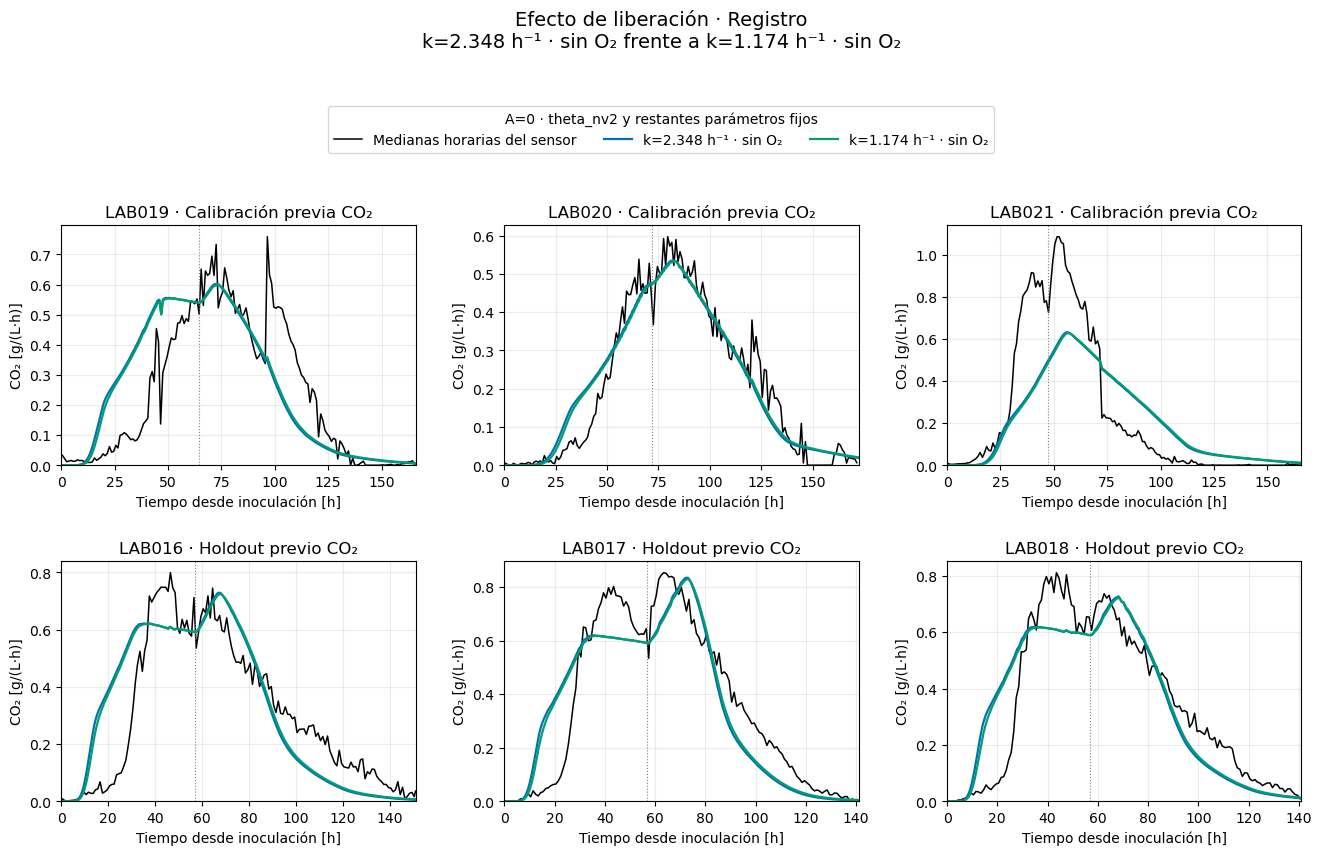

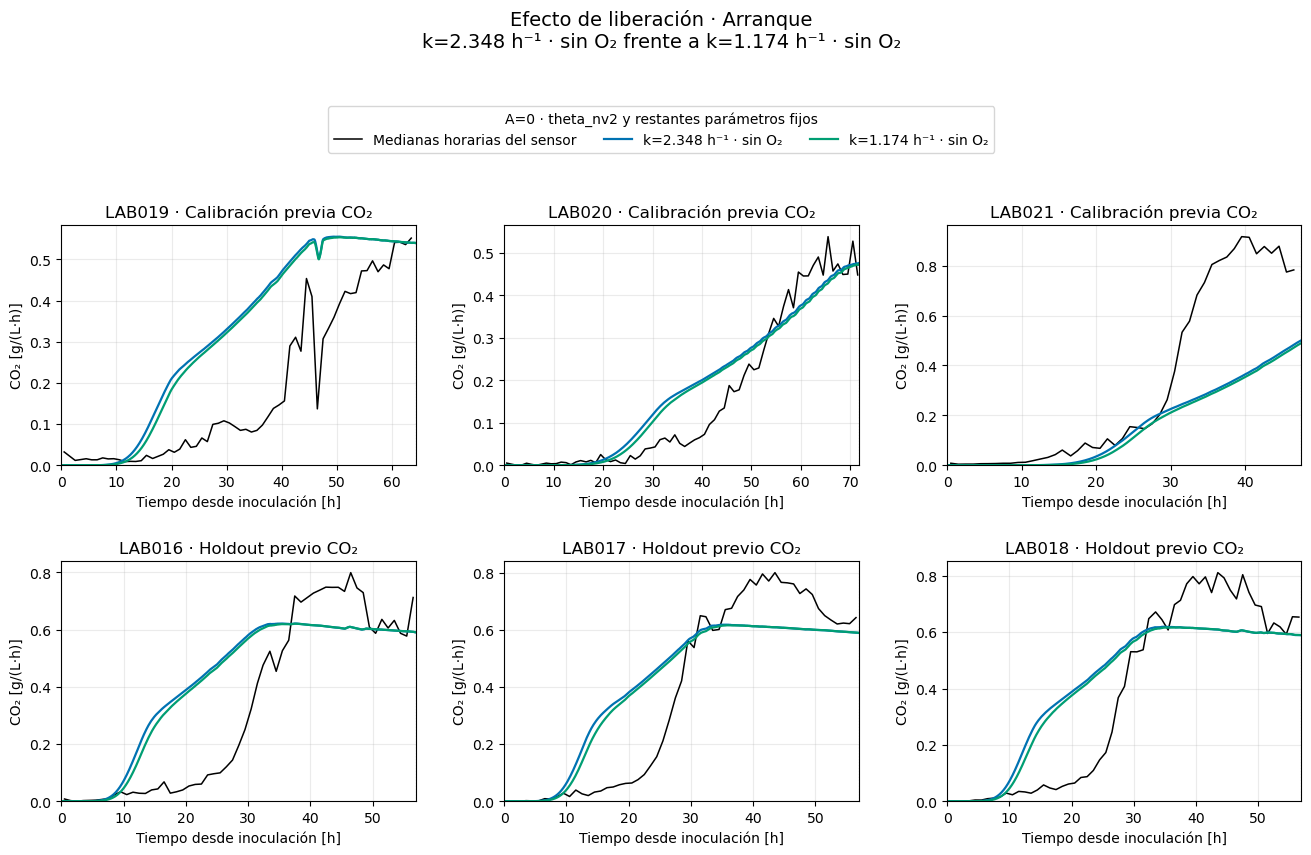

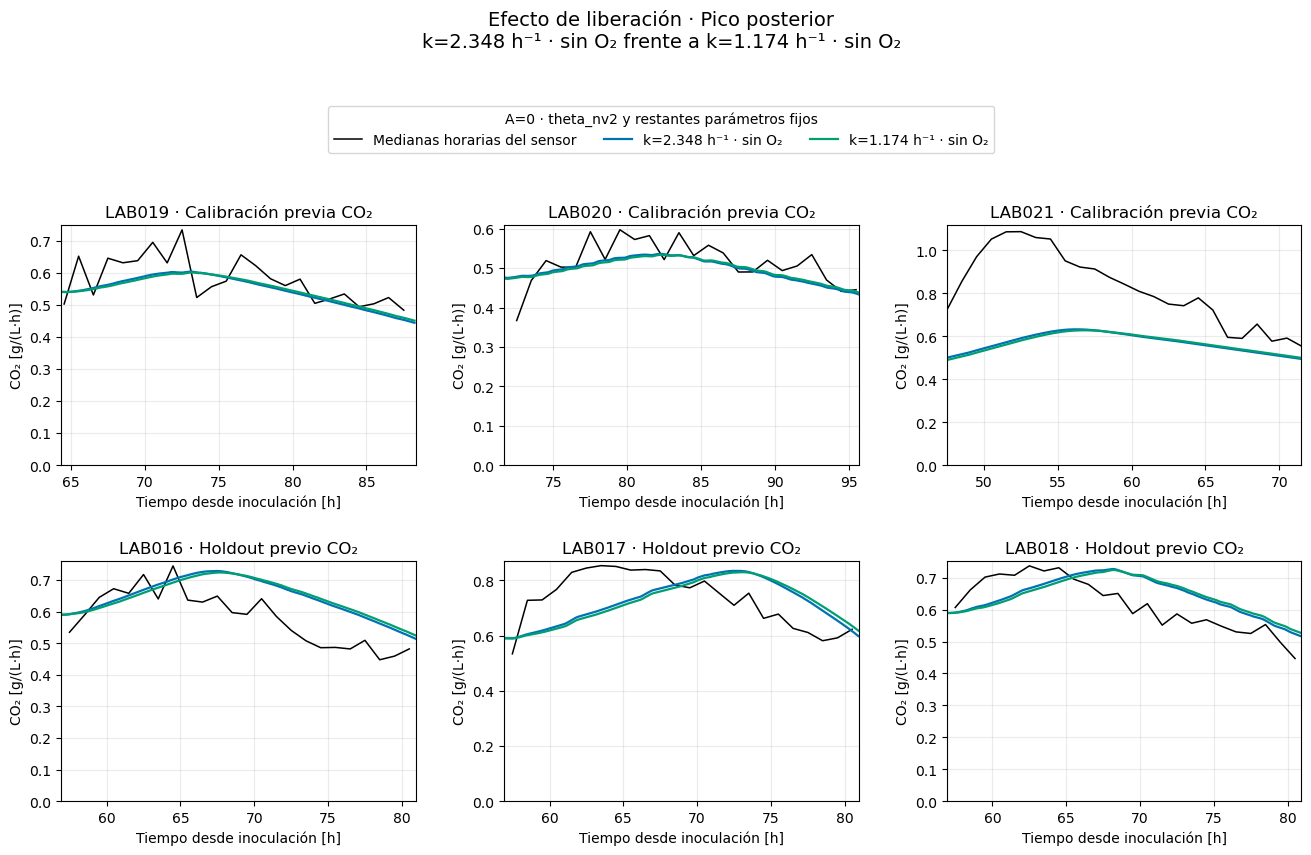

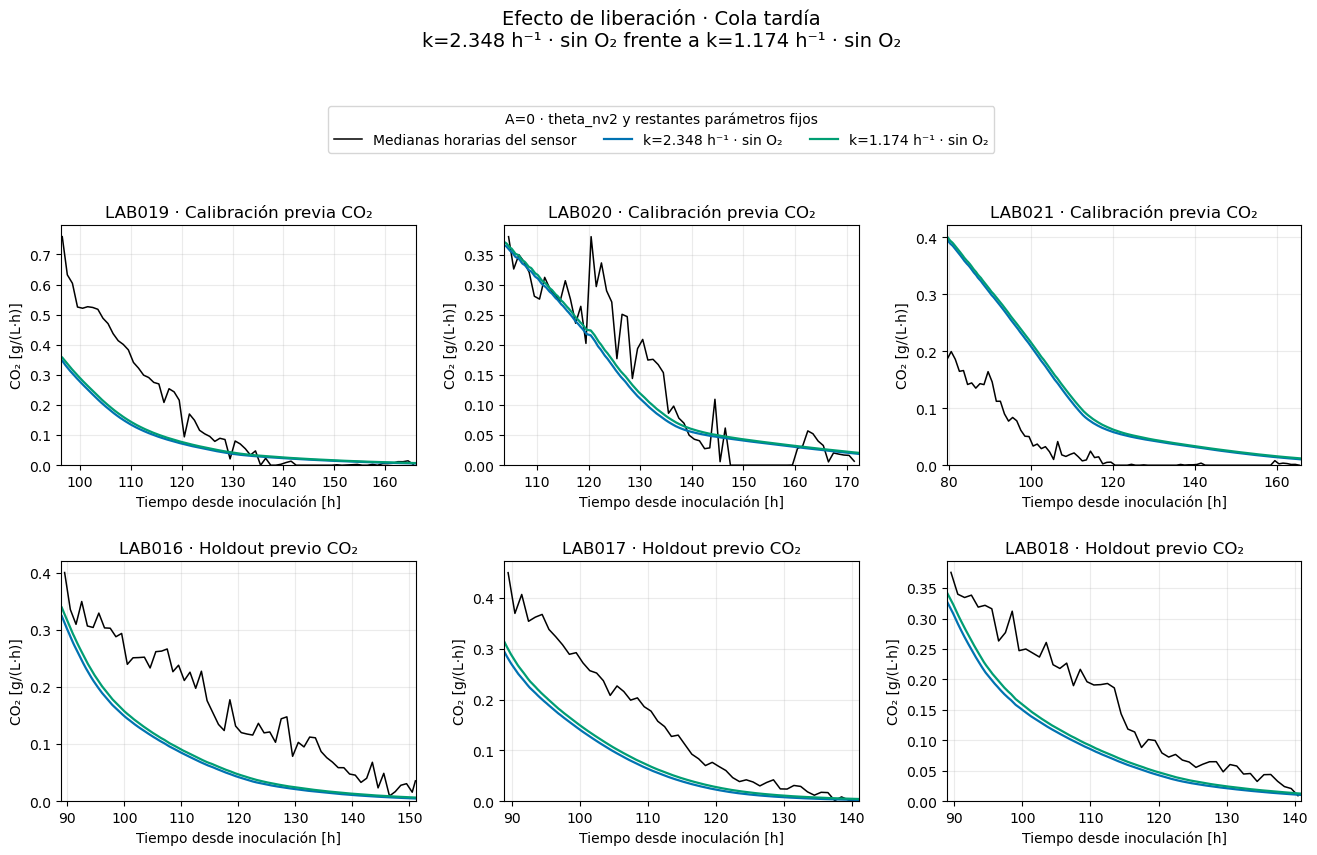

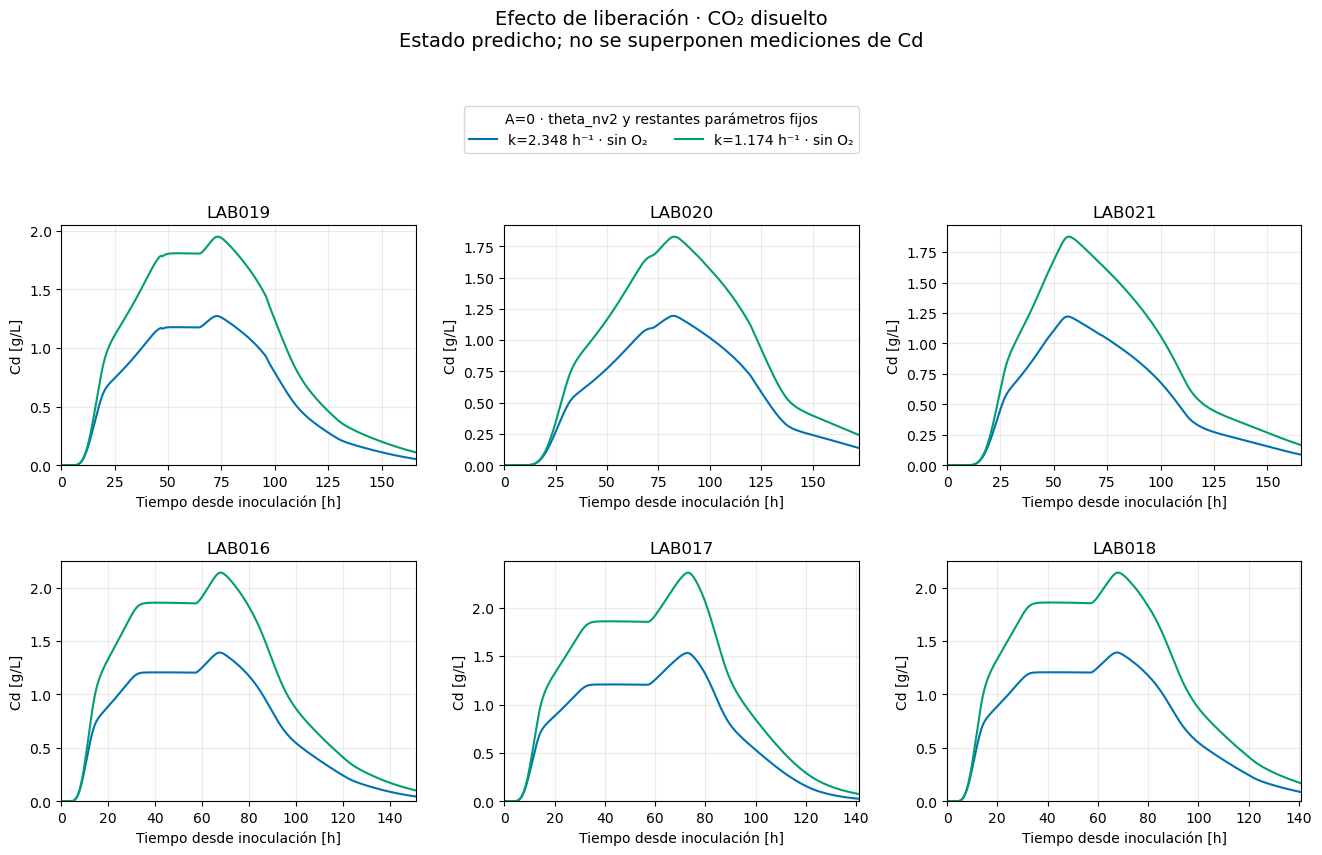

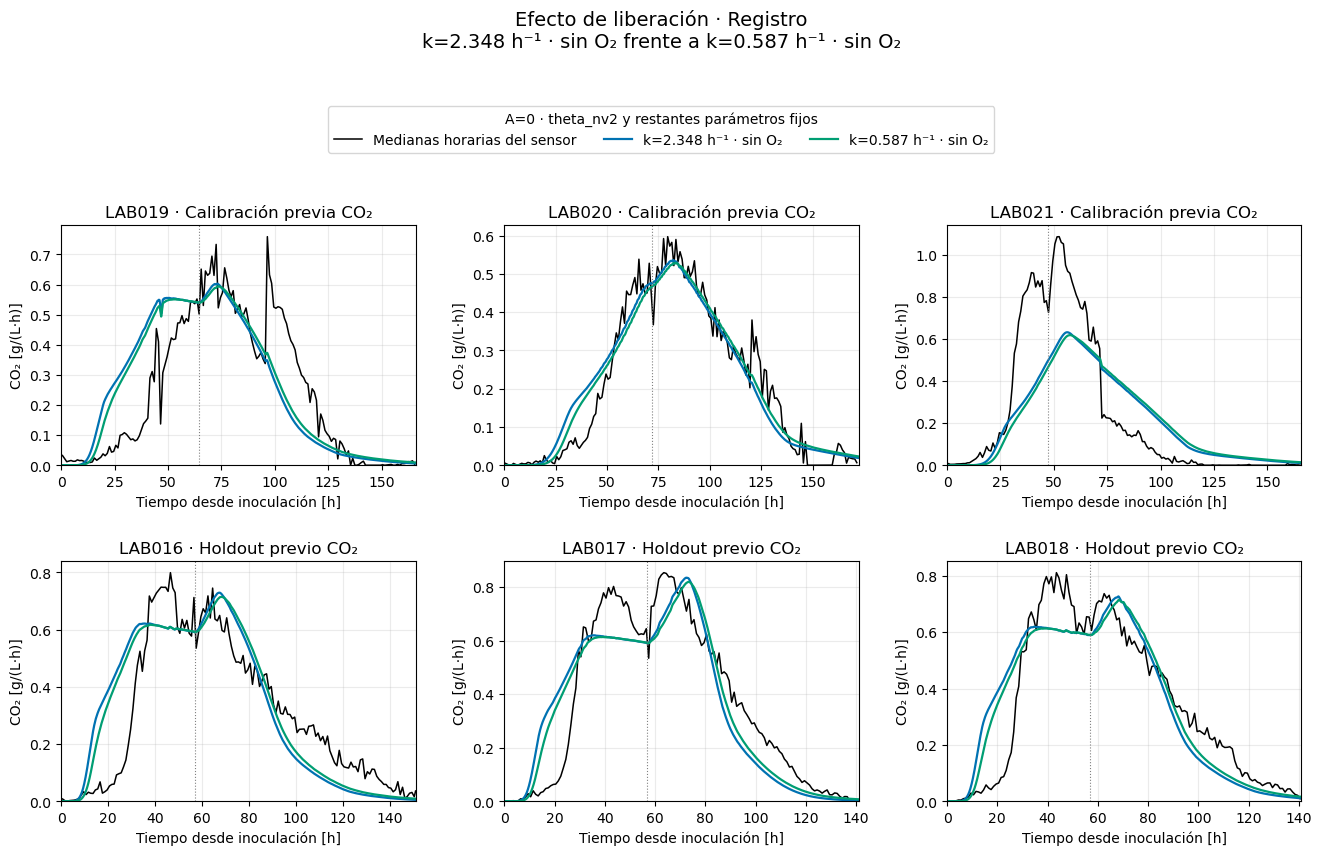

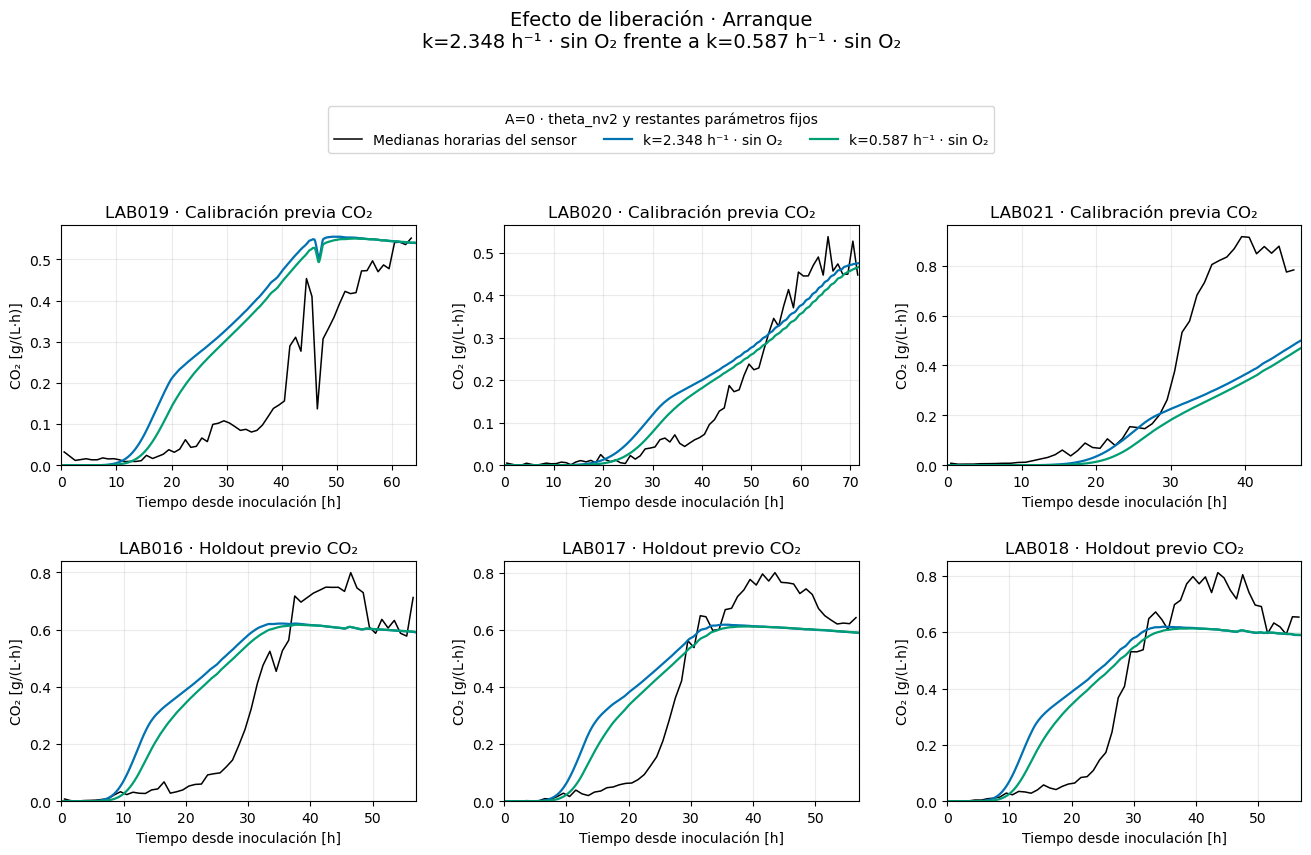

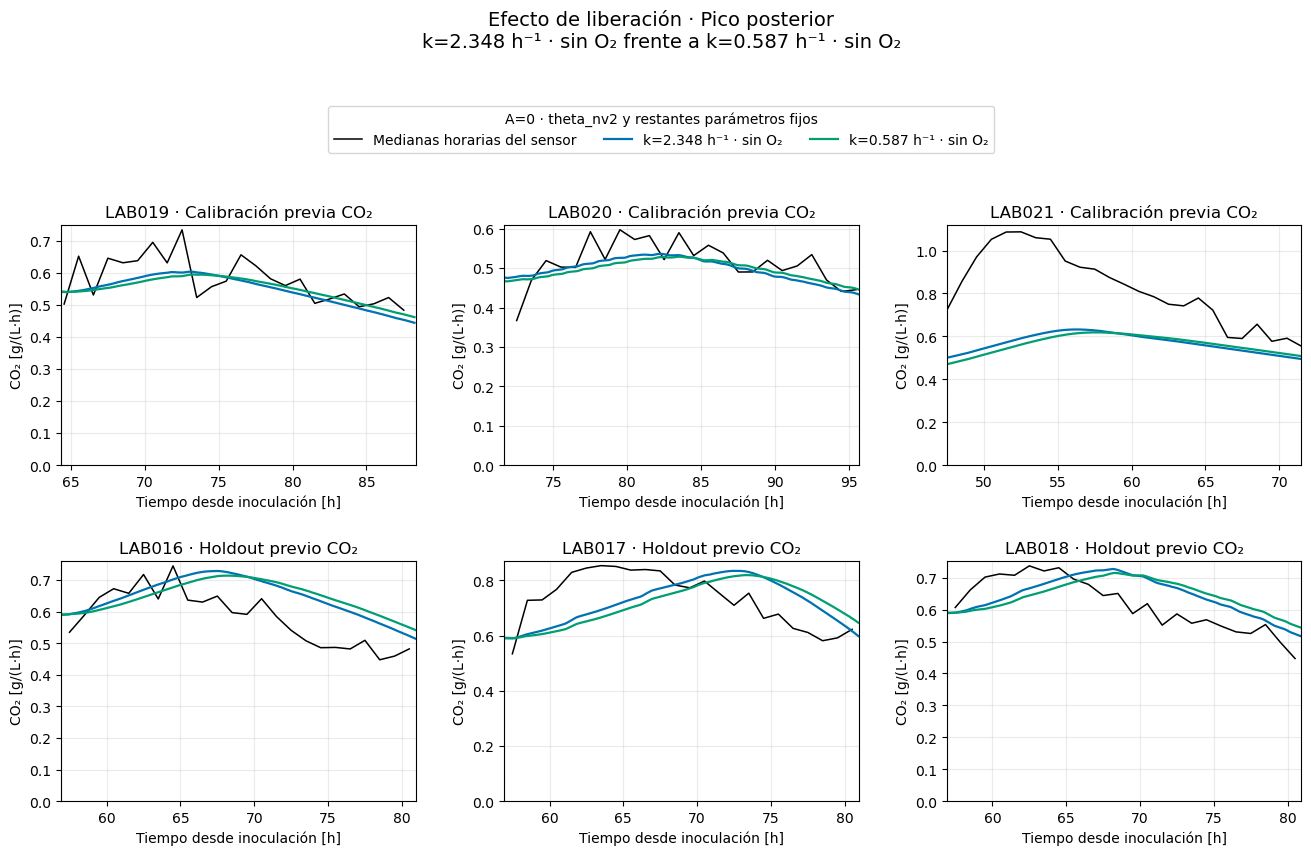

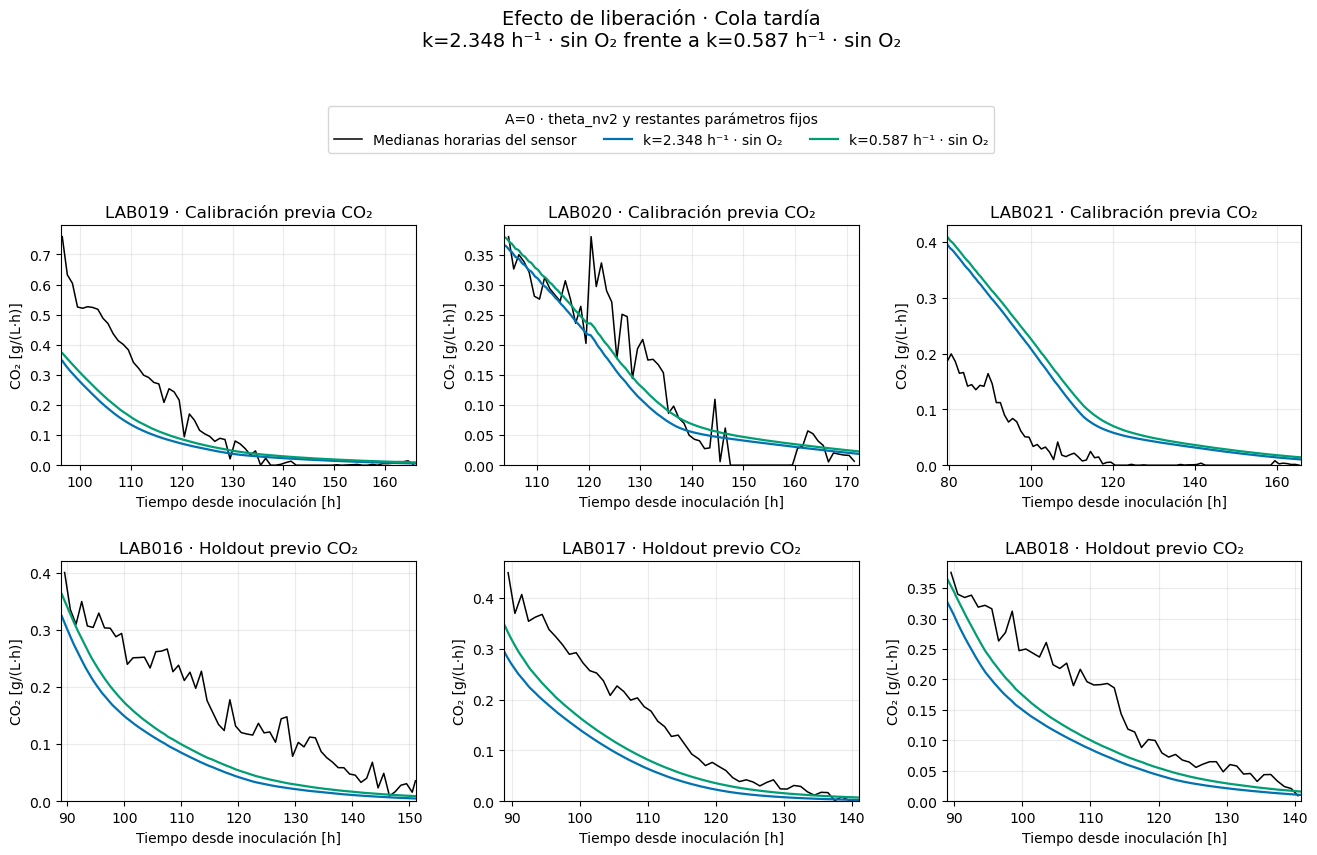

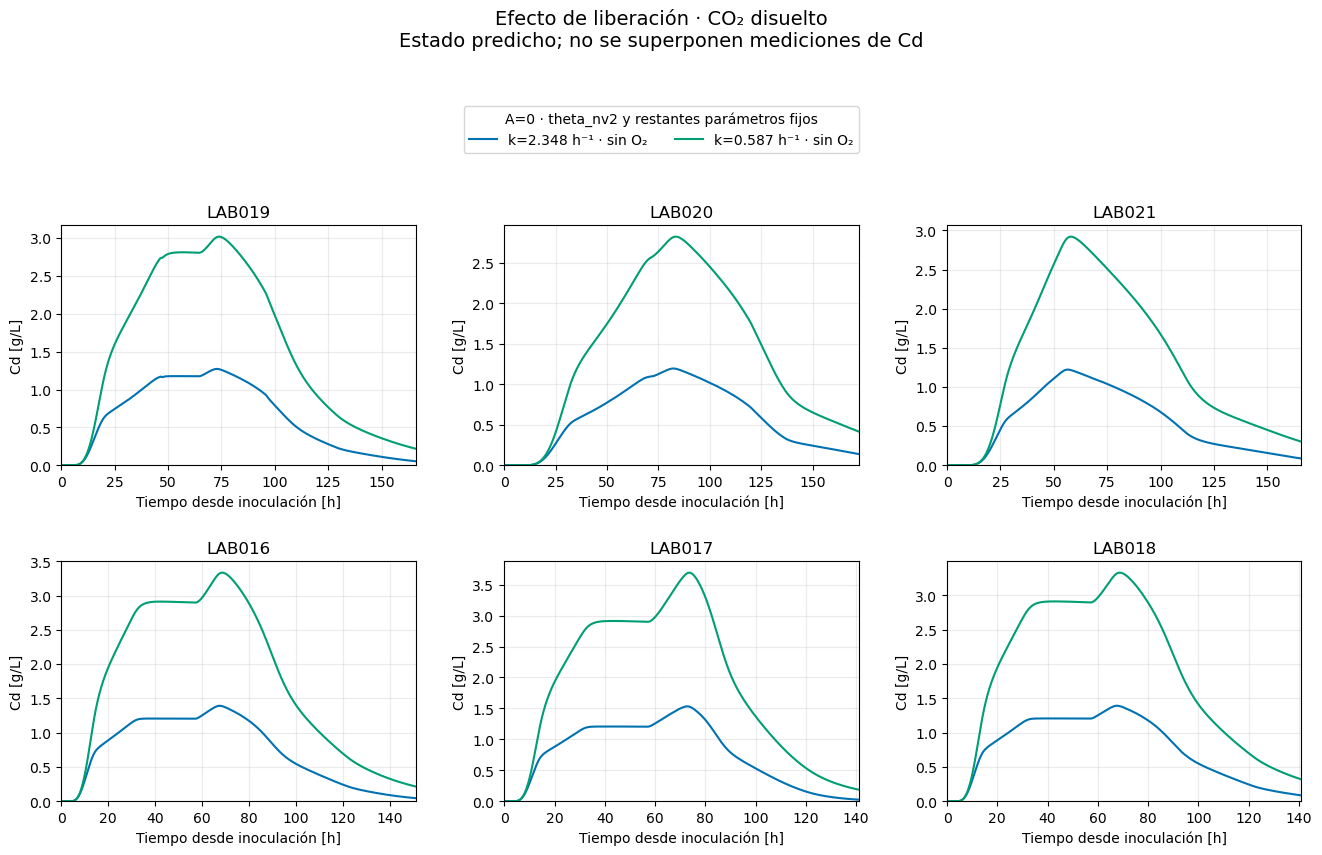

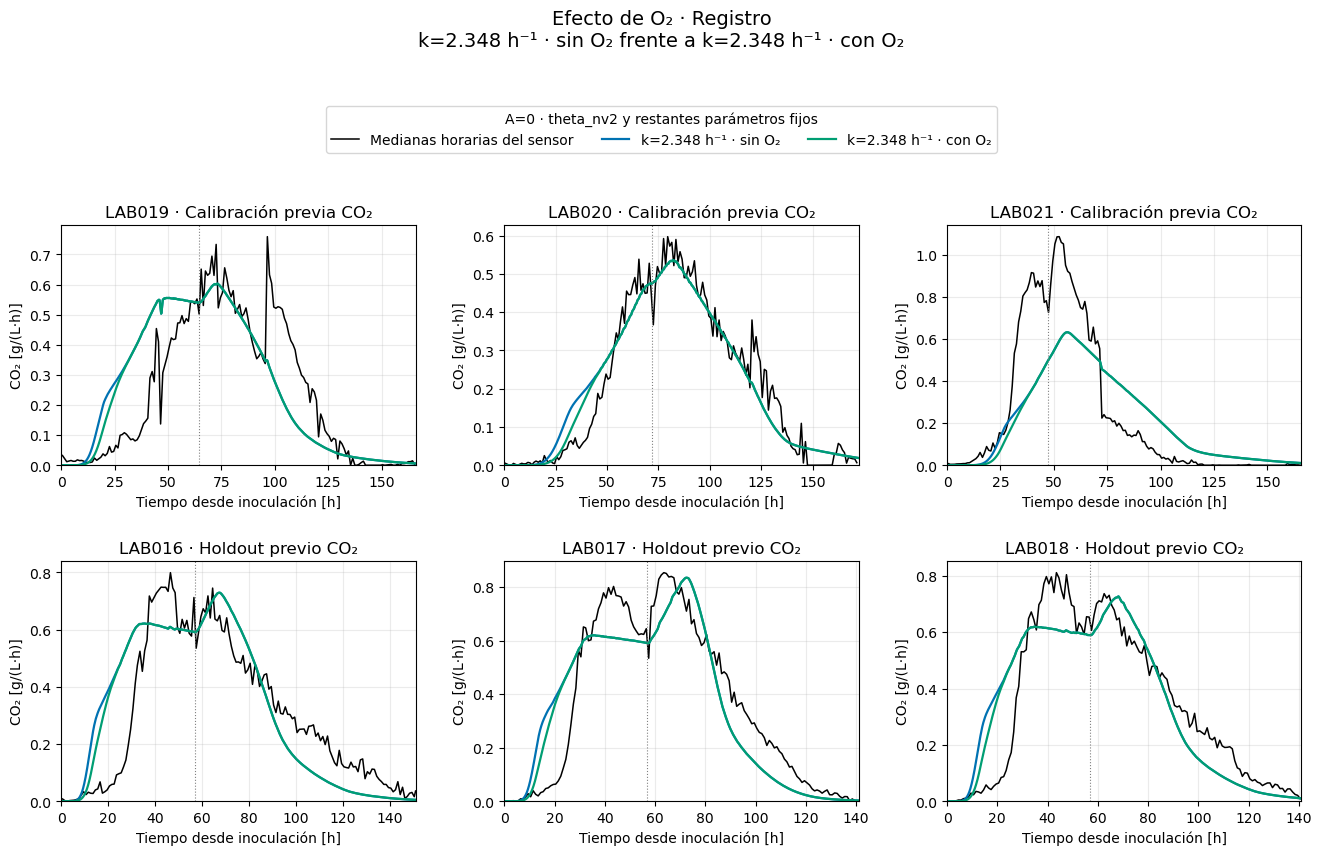

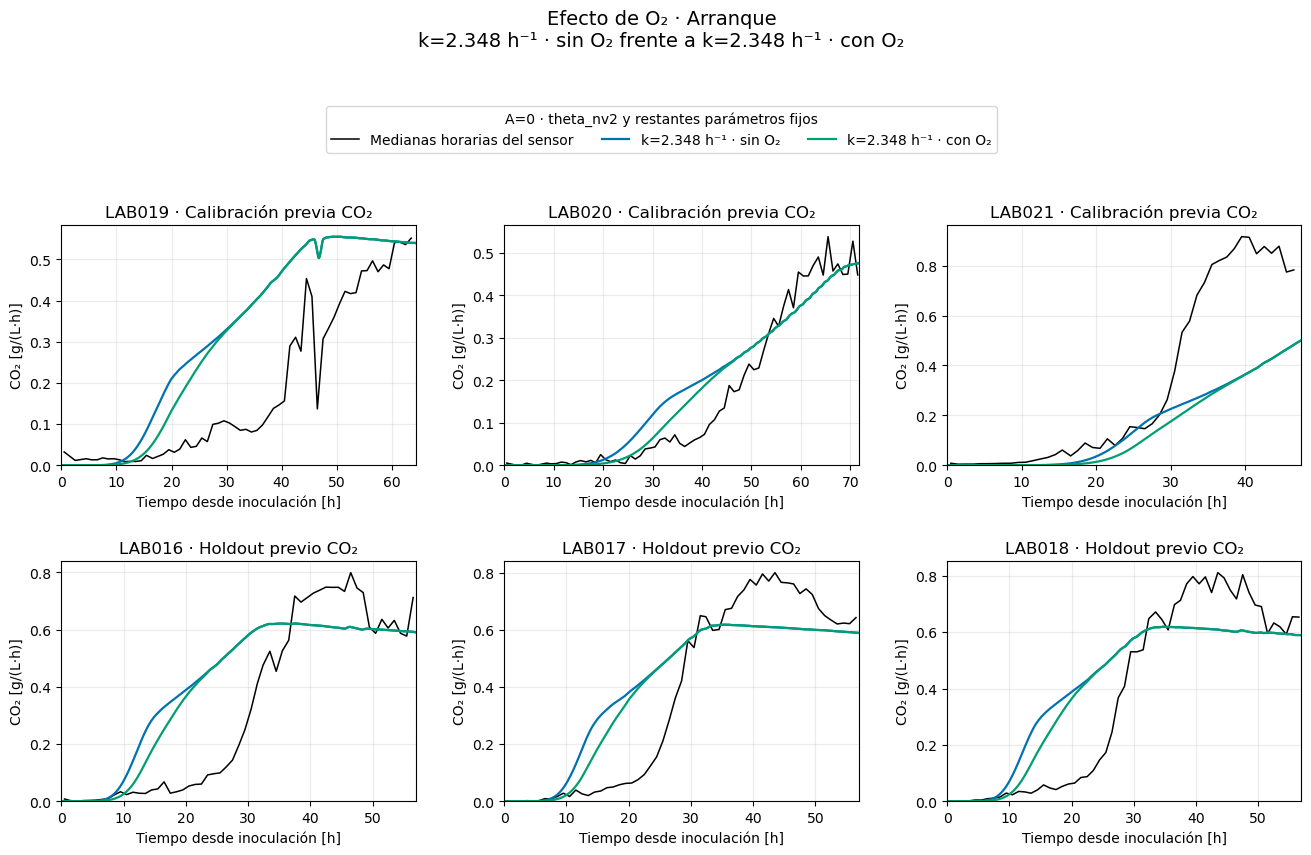

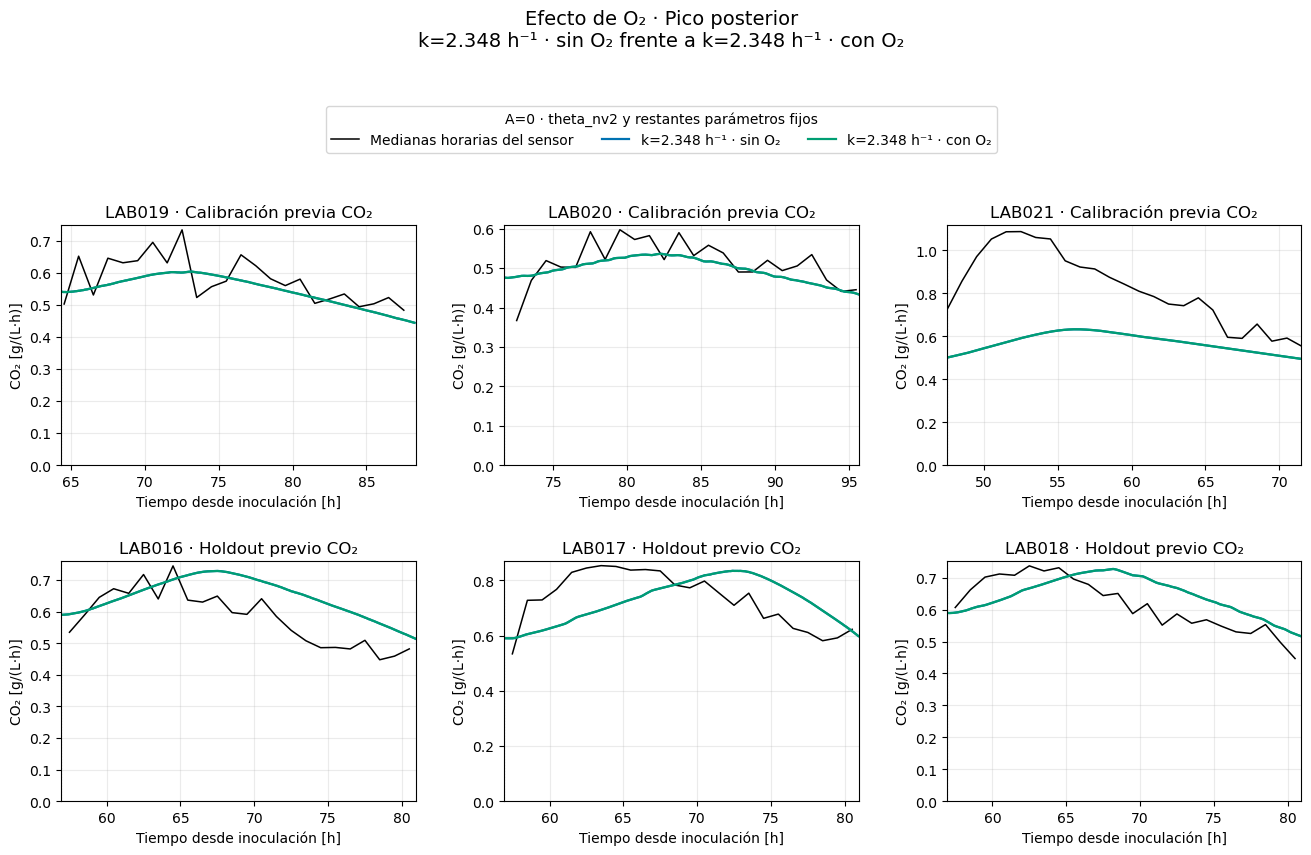

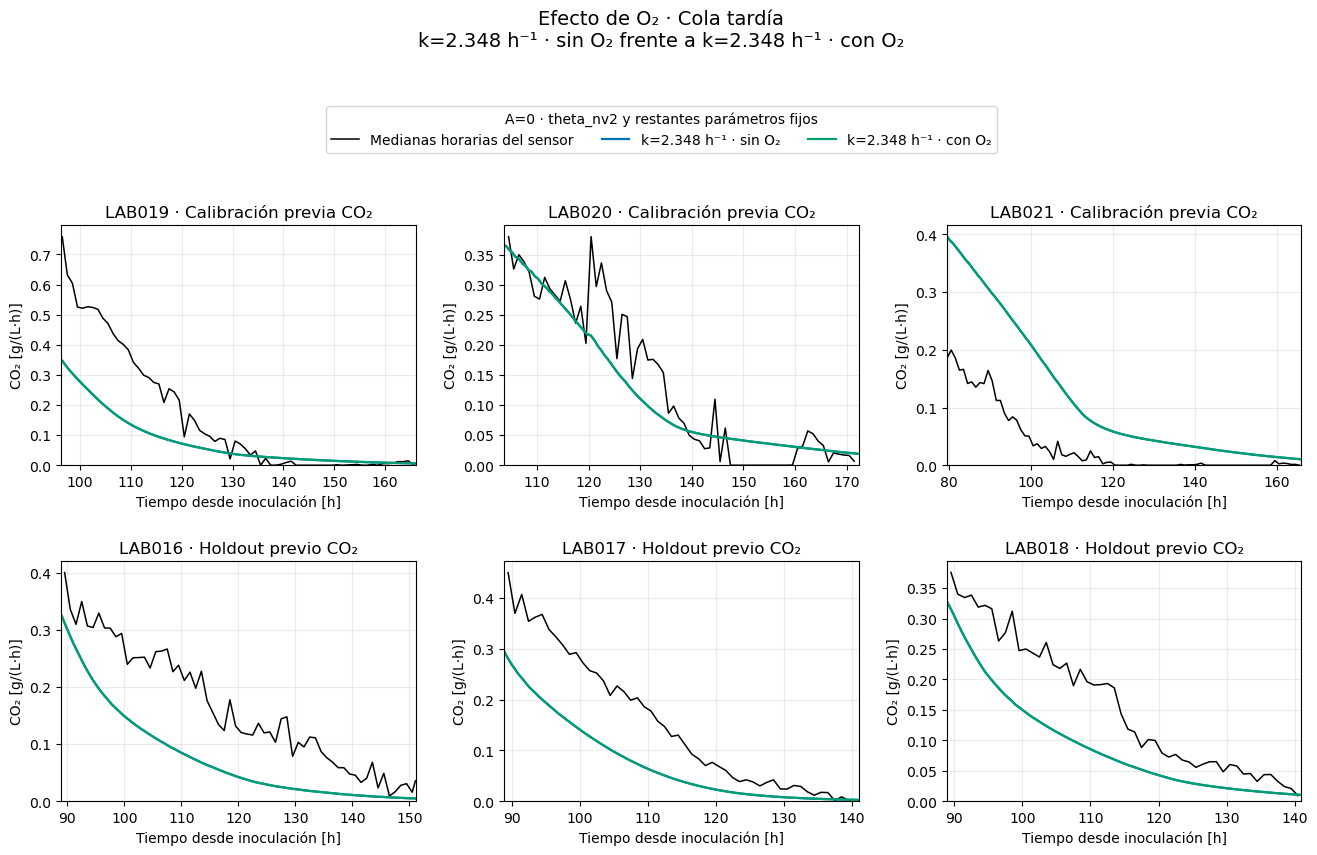

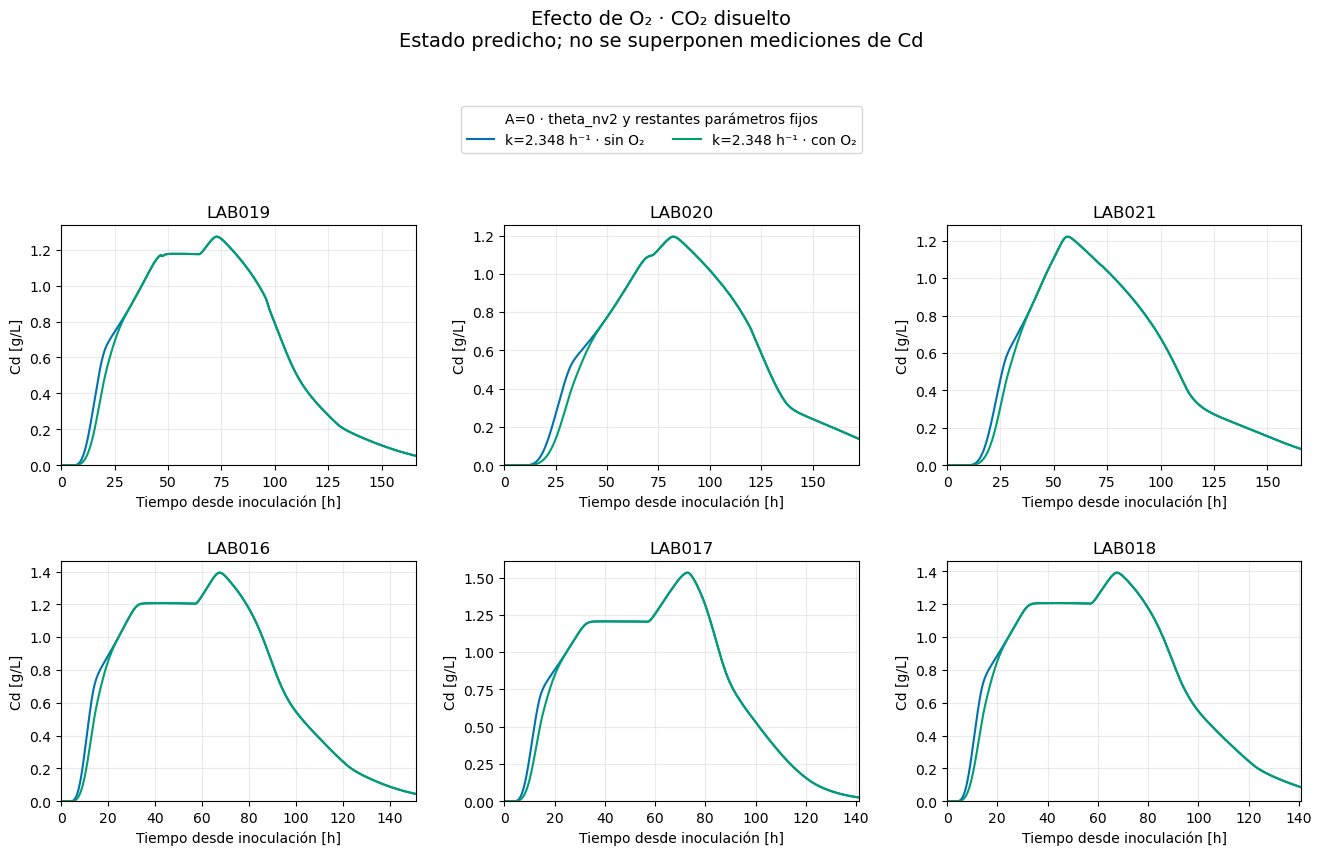

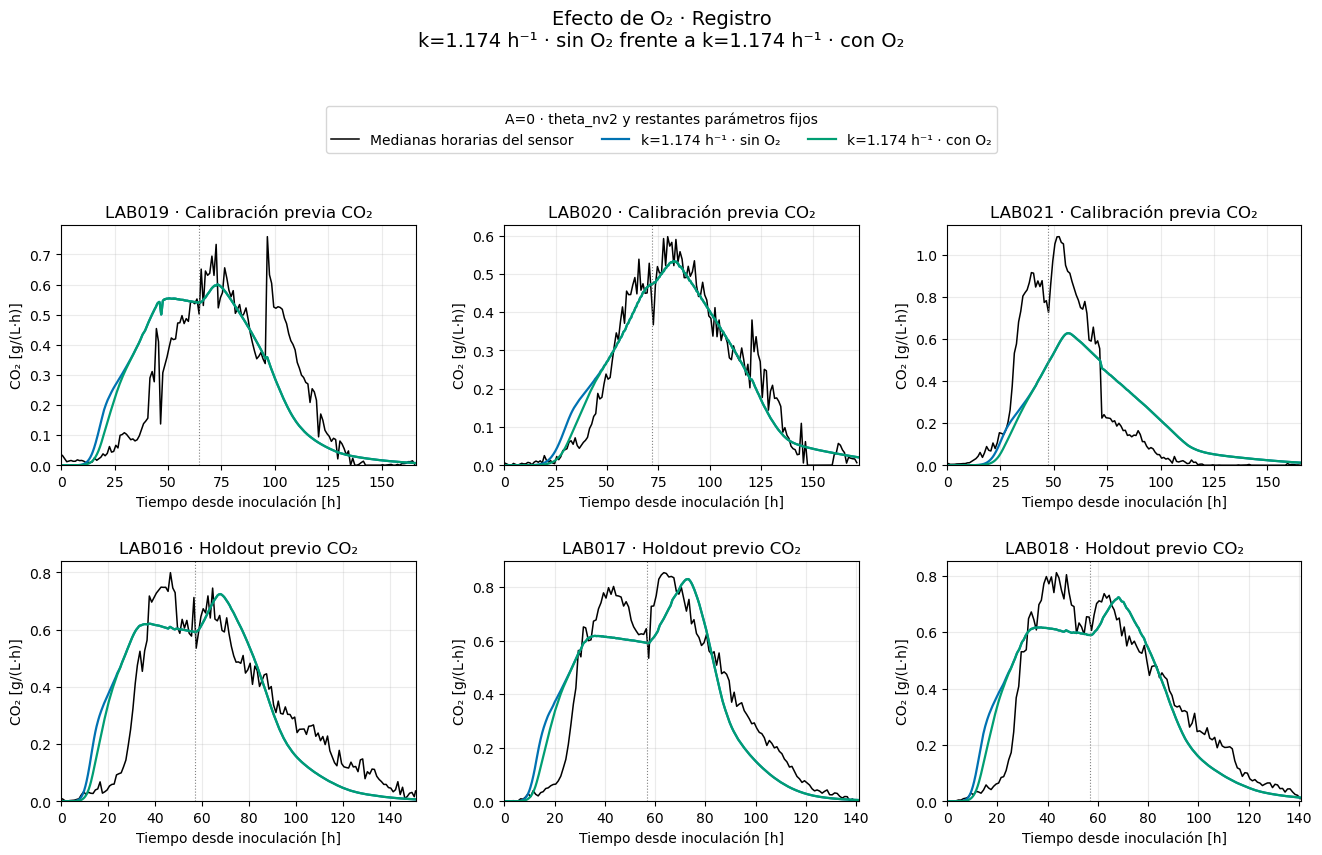

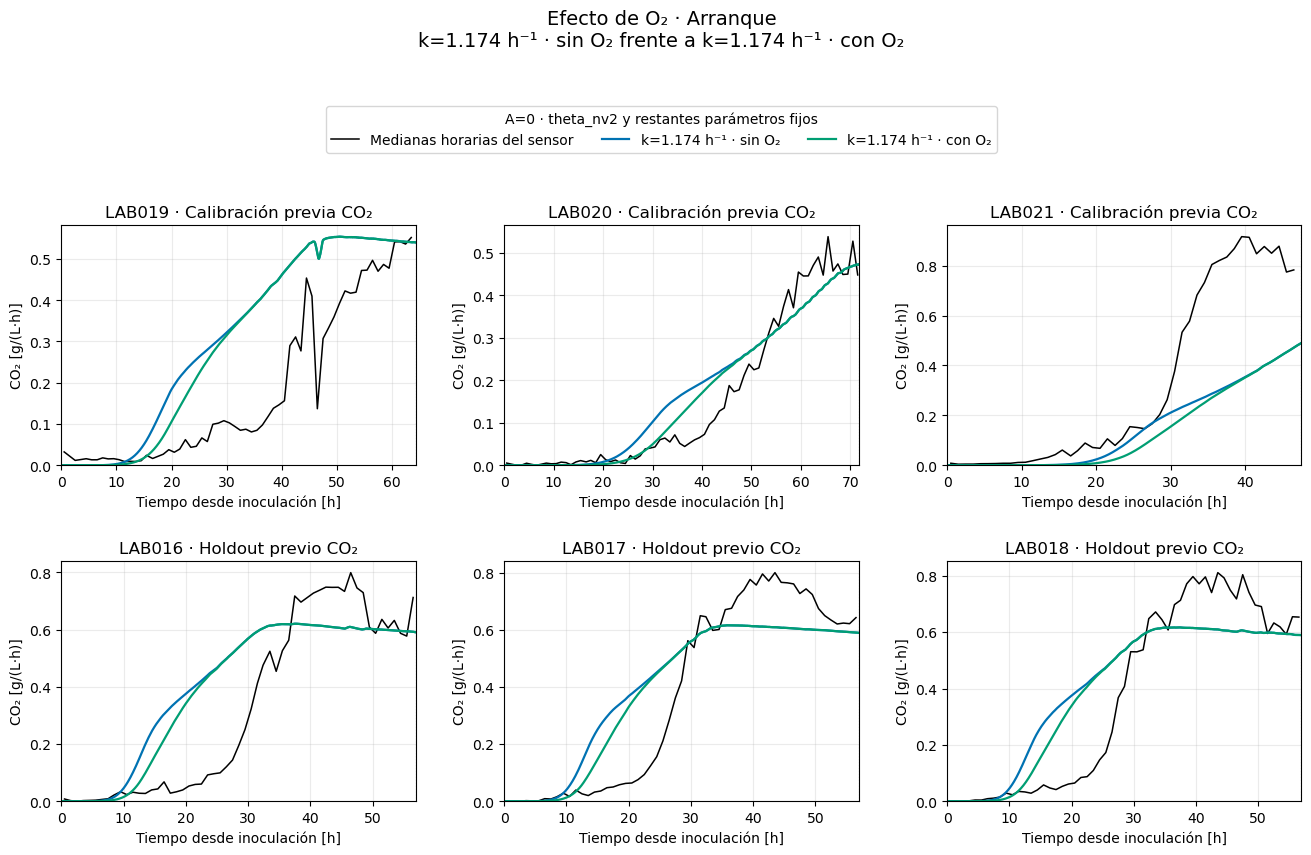

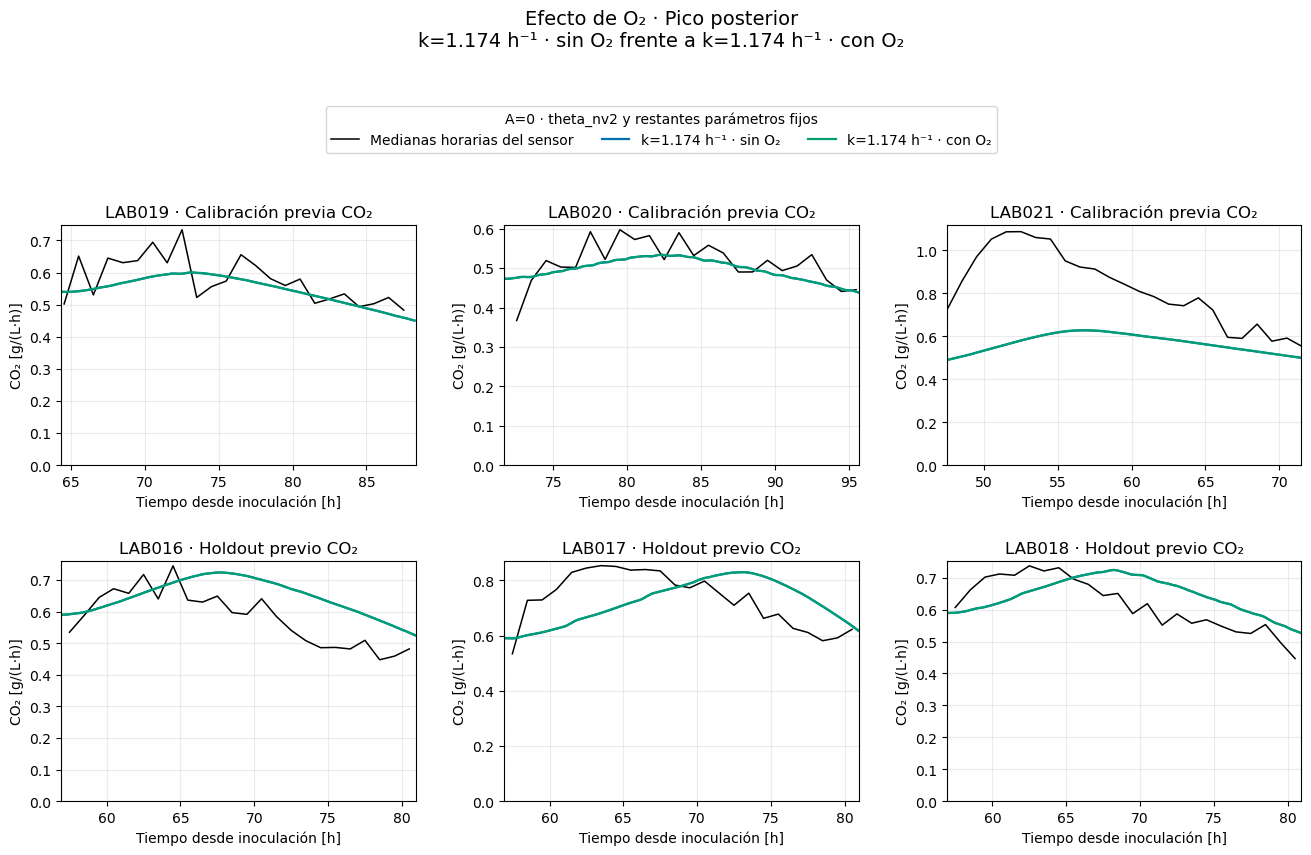

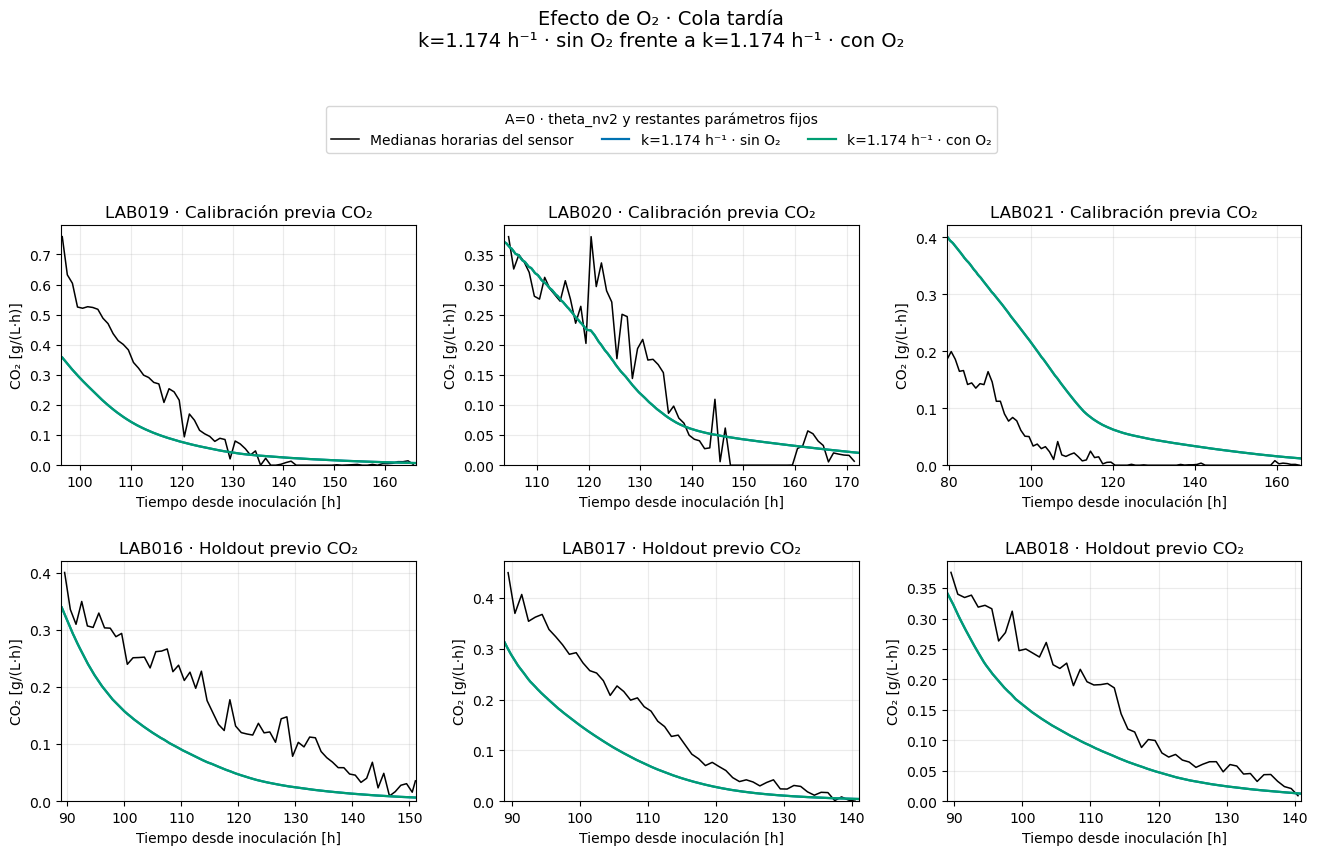

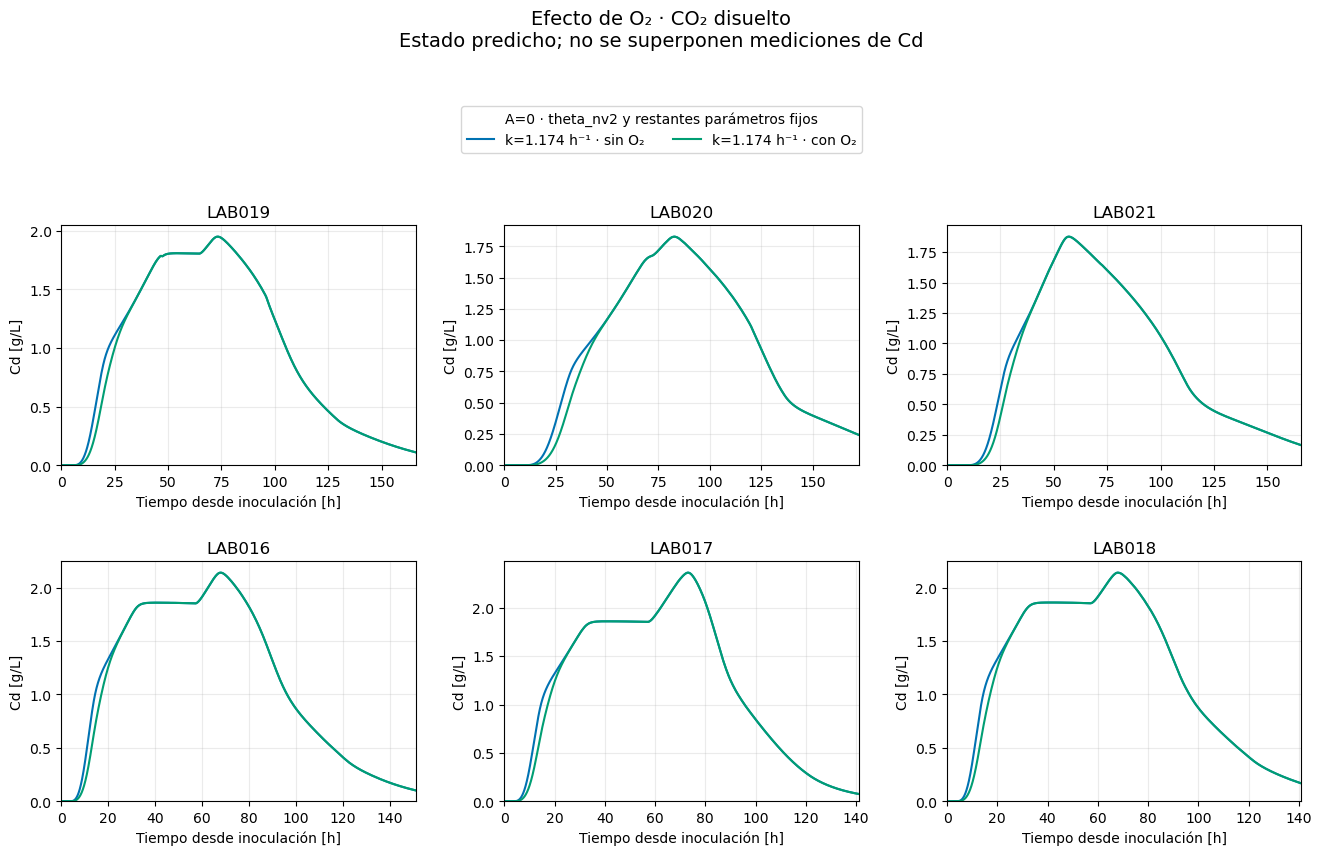

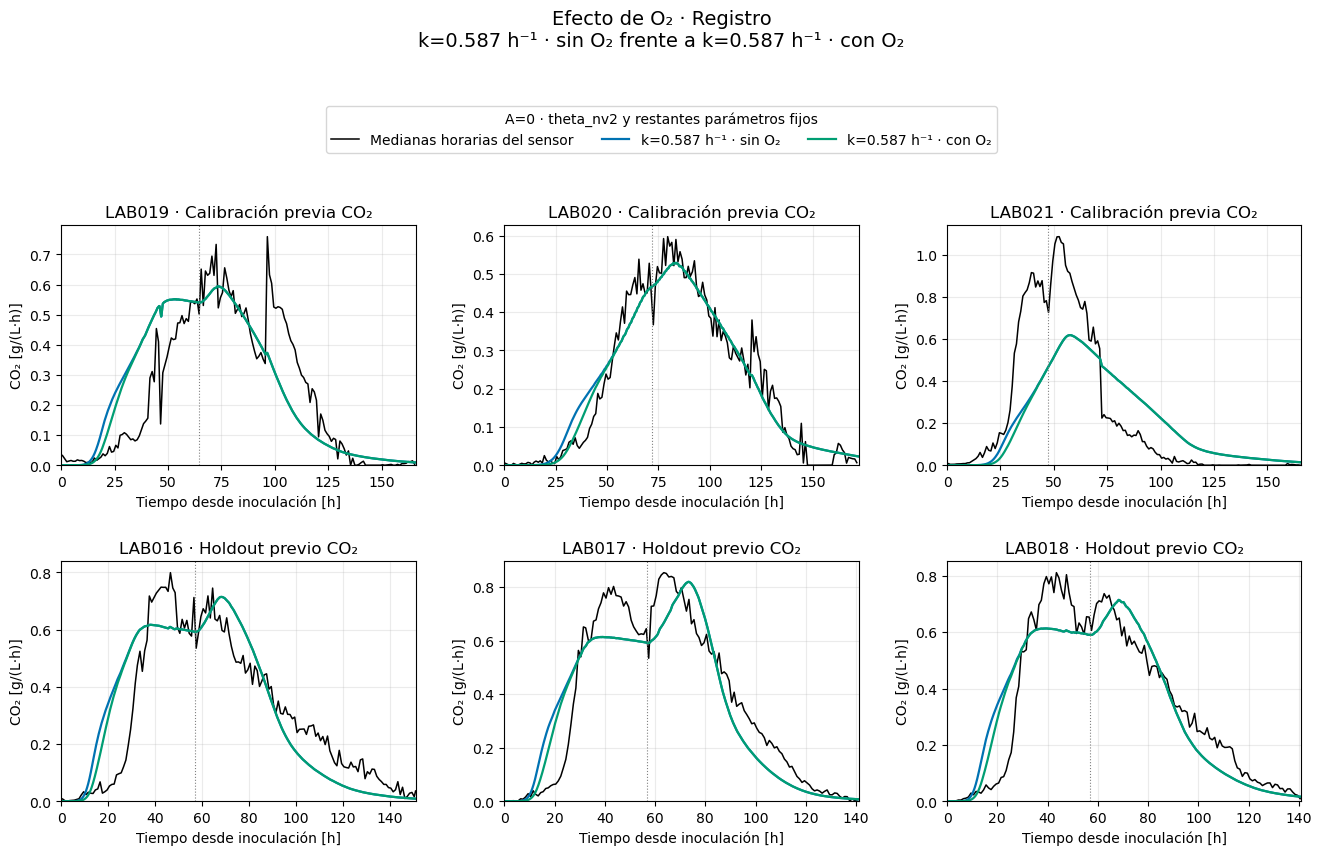

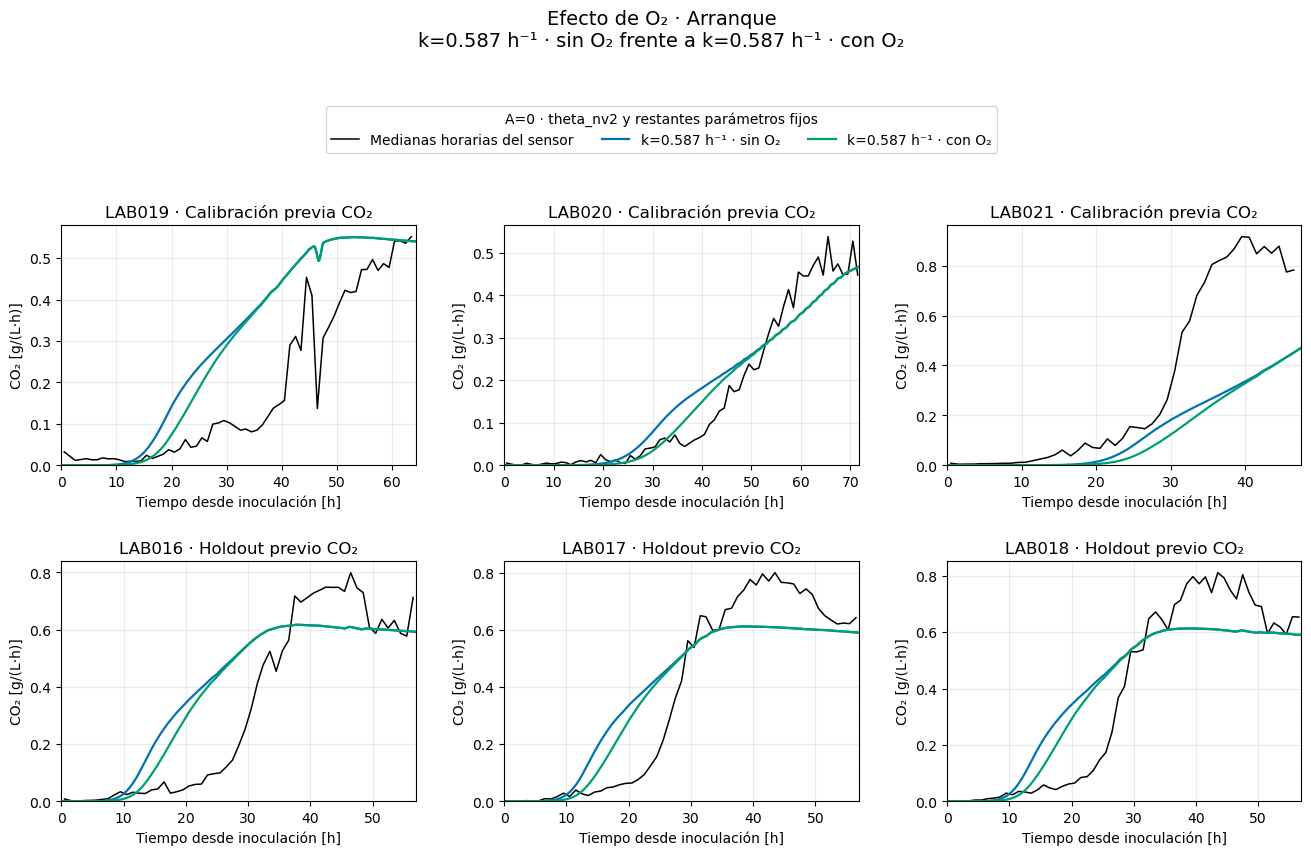

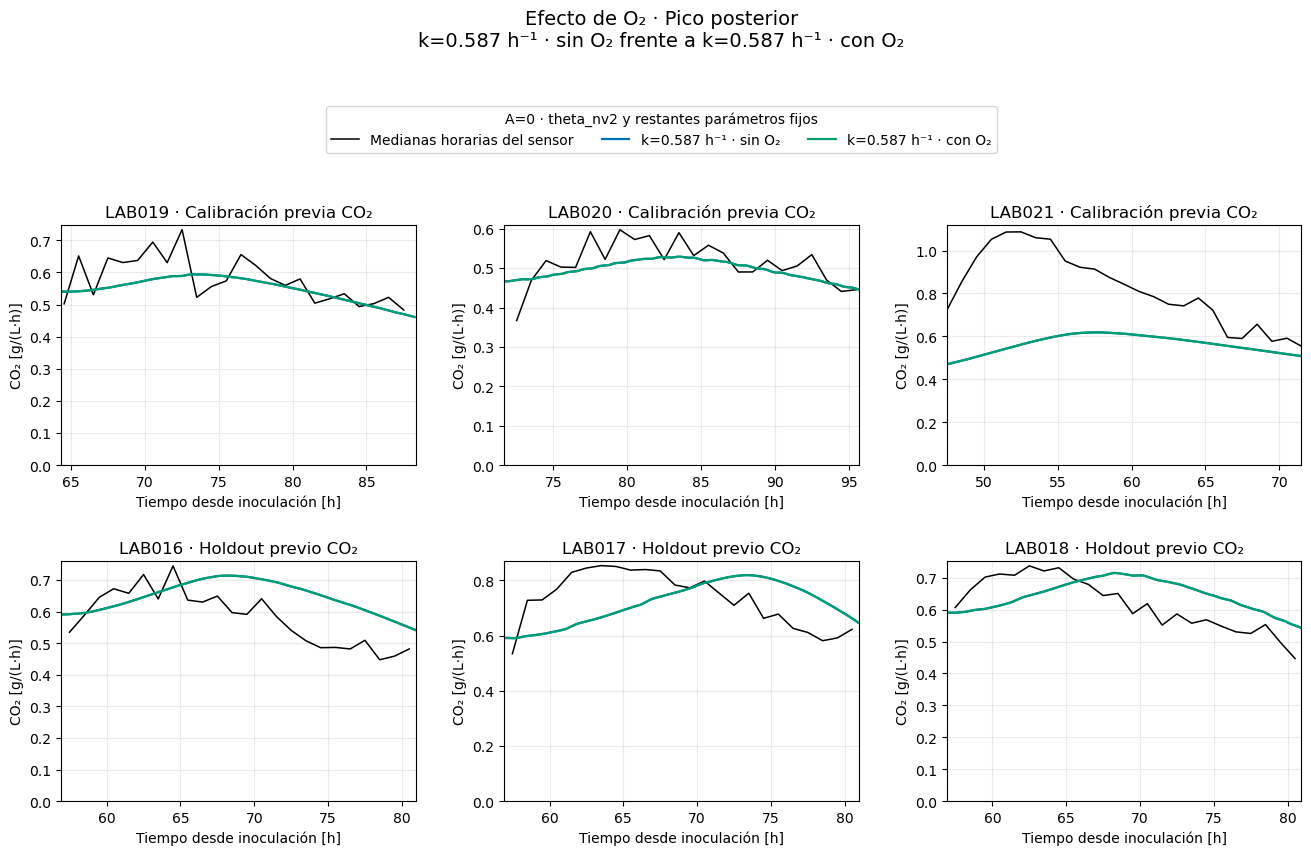

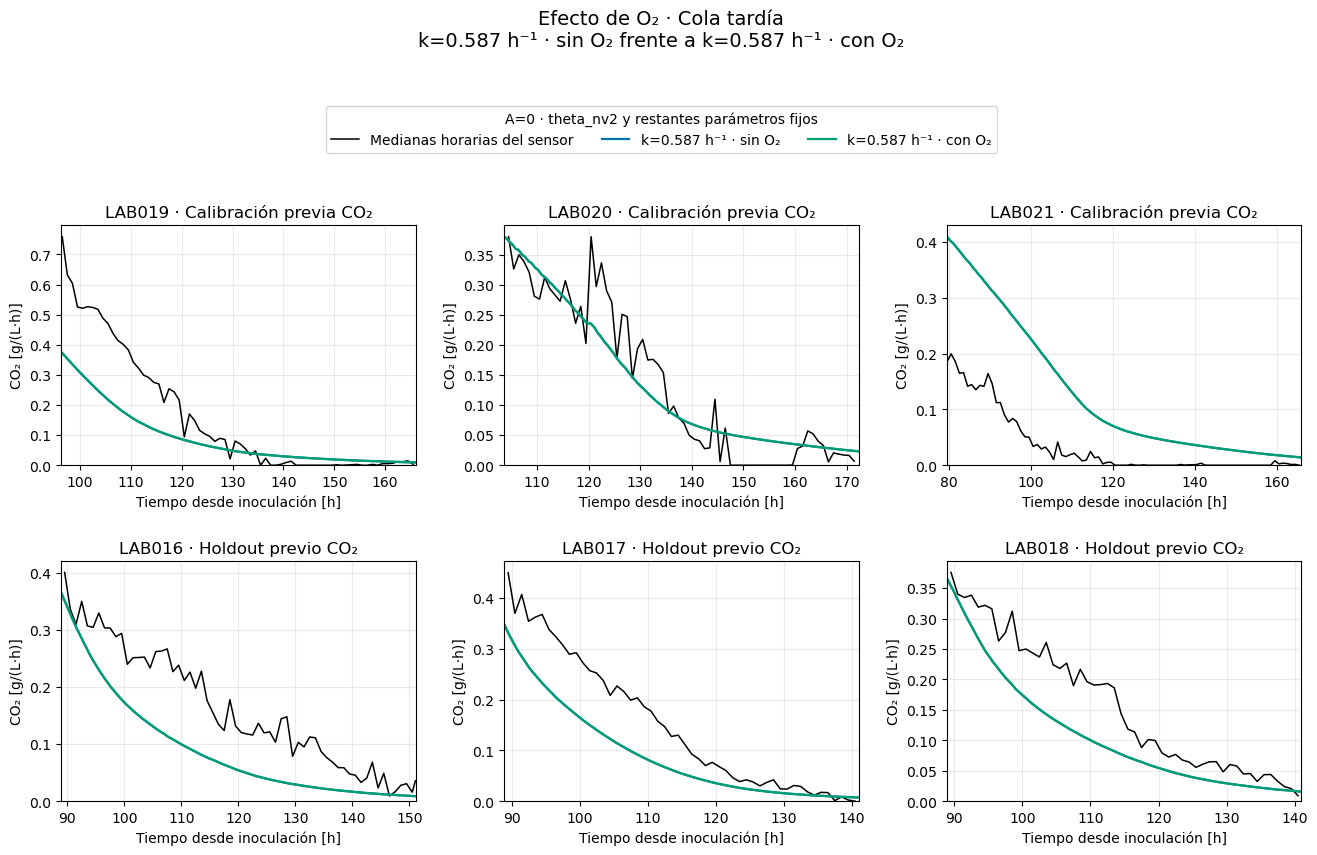

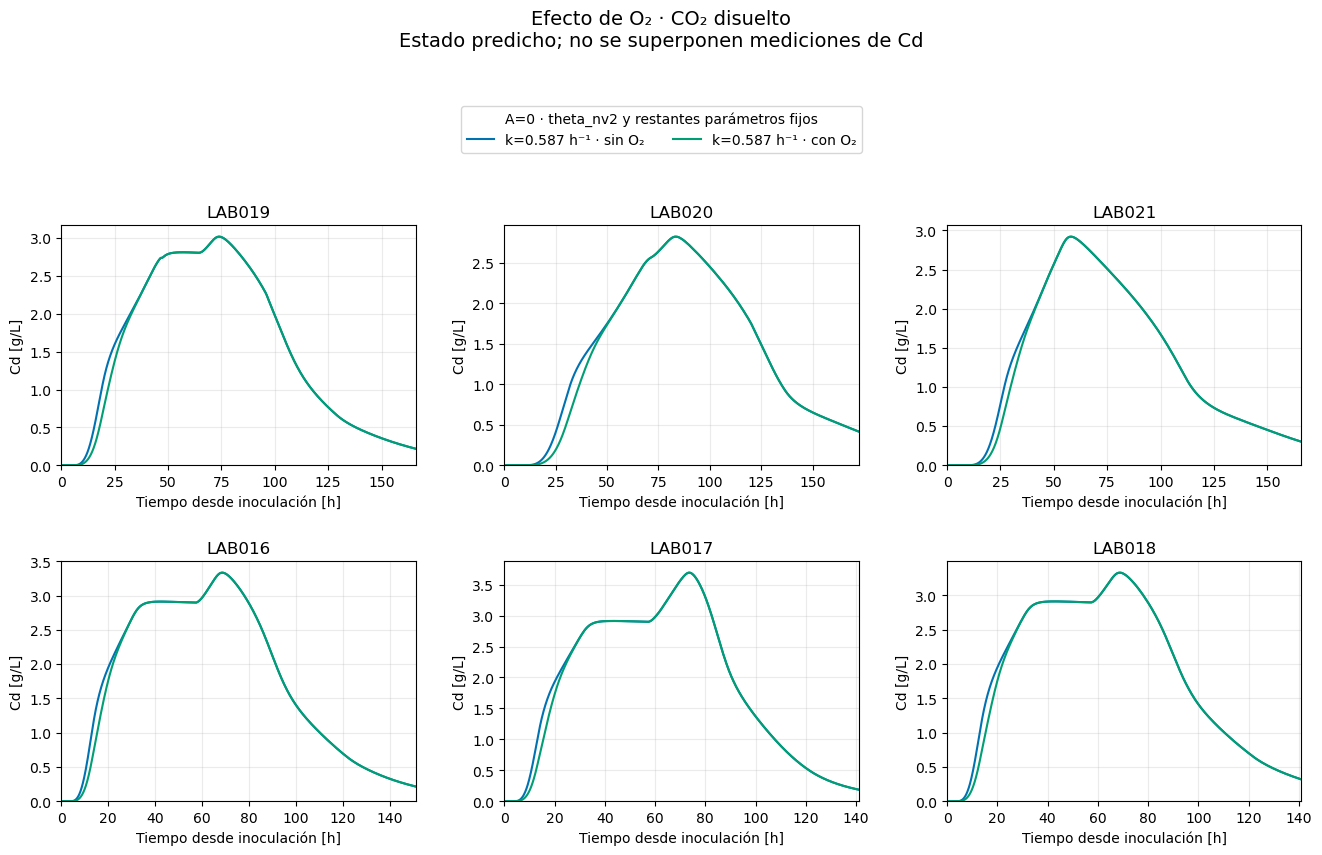

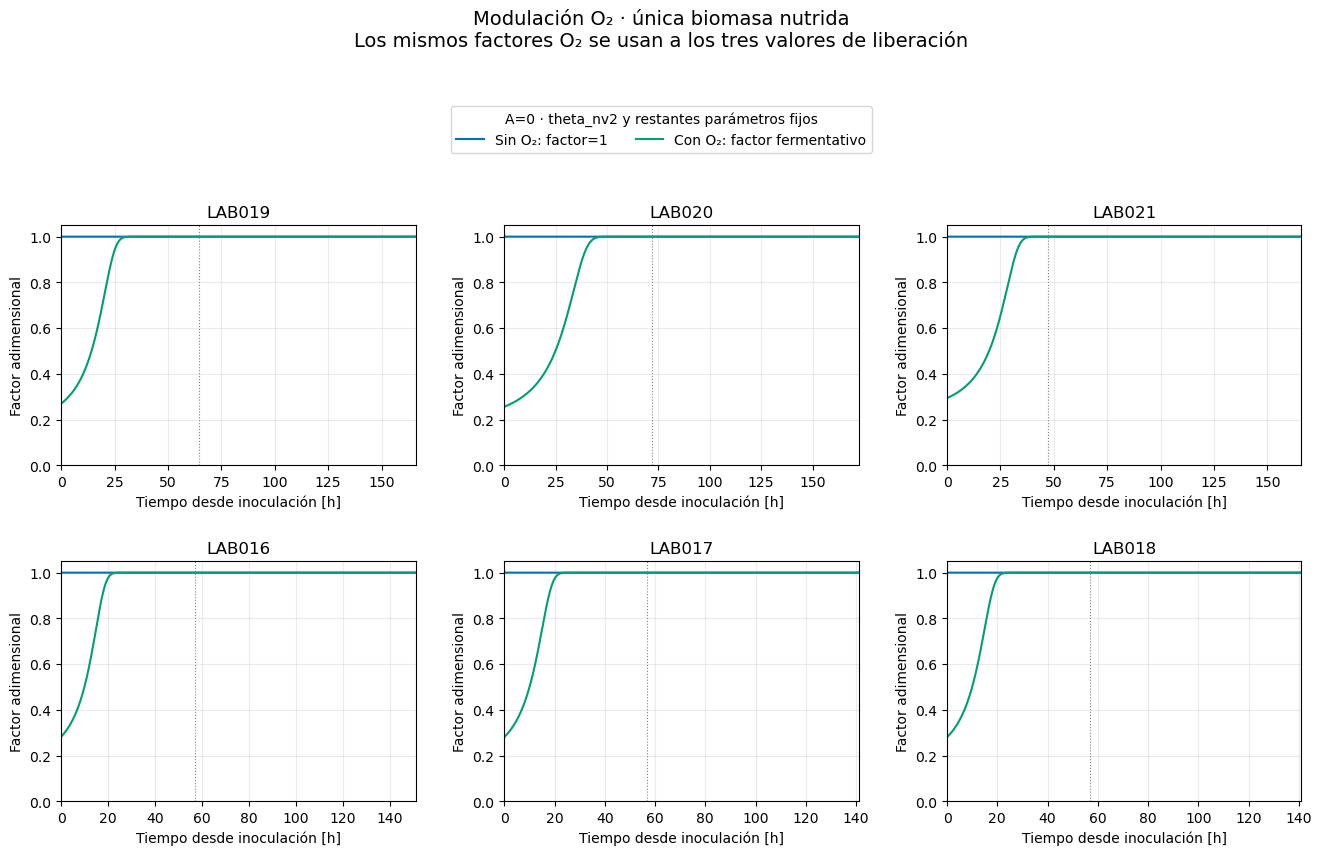

In [3]:
def label(j,on):return f'k={levels[j]:.3f} h⁻¹ · '+('con O₂' if on else 'sin O₂')
comparisons=[((0,False),(j,False),'Efecto de liberación') for j in [1,2]]
comparisons += [((j,False),(j,True),'Efecto de O₂') for j in range(3)]
def finish(fig,axes,title,subtitle):
 items={}
 for ax in axes.flat:
  hh,ll=ax.get_legend_handles_labels()
  for h,l in zip(hh,ll):items.setdefault(l,h)
 fig.suptitle(title+'\n'+subtitle,y=.99,fontsize=14)
 fig.legend(items.values(),items.keys(),loc='upper center',bbox_to_anchor=(.5,.89),ncol=3,title='A=0 · theta_nv2 y restantes parámetros fijos')
 fig.subplots_adjust(top=.75,hspace=.4,wspace=.25);plt.show()
for pair1,pair2,description in comparisons:
 for window in ['Registro','Arranque','Pico posterior','Cola tardía']:
  fig,axes=plt.subplots(2,3,figsize=(16,9))
  for ax,lab in zip(axes.flat,LABS):
   start,end=windows[lab][window];o=support[lab];o=o.loc[o.time_h.between(start,end)]
   ax.plot(o.time_h,o.co2_raw_g_l_h,color='black',lw=1.1,label='Medianas horarias del sensor')
   for pair,color in [(pair1,'#0072B2'),(pair2,'#009E73')]:
    f=curves[*pair,lab];m=(f.index>=start)&(f.index<=end)
    ax.plot(f.index[m],f.qpred[m],color=color,lw=1.6,label=label(*pair))
   for tp,d in batches[lab].pulses['N']:
    if start<=tp<=end:ax.axvline(tp,color='.5',ls=':',lw=.8)
   ax.set(title=lab+(' · Calibración previa CO₂' if lab in LABS[:3] else ' · Holdout previo CO₂'),
    xlabel='Tiempo desde inoculación [h]',ylabel='CO₂ [g/(L·h)]',xlim=(start,end))
   ax.set_ylim(bottom=0);ax.grid(alpha=.25)
  finish(fig,axes,description+' · '+window,label(*pair1)+' frente a '+label(*pair2))
 # Memory of the reservoir: no fabricated dissolved-CO2 observations.
 fig,axes=plt.subplots(2,3,figsize=(16,9))
 for ax,lab in zip(axes.flat,LABS):
  for pair,color in [(pair1,'#0072B2'),(pair2,'#009E73')]:
   f=curves[*pair,lab].loc[:v.horizons[lab]];ax.plot(f.index,f.Cd,color=color,label=label(*pair))
  ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='Cd [g/L]',xlim=(0,v.horizons[lab]));ax.set_ylim(bottom=0);ax.grid(alpha=.25)
 finish(fig,axes,description+' · CO₂ disuelto','Estado predicho; no se superponen mediciones de Cd')
fig,axes=plt.subplots(2,3,figsize=(16,9))
for ax,lab in zip(axes.flat,LABS):
 c=contexts[lab];ax.plot(c['time'],np.ones(len(c['time'])),color='#0072B2',label='Sin O₂: factor=1')
 ax.plot(c['time'],factors[lab],color='#009E73',label='Con O₂: factor fermentativo')
 for tp,d in batches[lab].pulses['N']:ax.axvline(tp,color='.5',ls=':',lw=.8)
 ax.set(title=lab,xlabel='Tiempo desde inoculación [h]',ylabel='Factor adimensional',xlim=(0,v.horizons[lab]),ylim=(0,1.05));ax.grid(alpha=.25)
finish(fig,axes,'Modulación O₂ · única biomasa nutrida','Los mismos factores O₂ se usan a los tres valores de liberación')


In [4]:
assert theta==theta_before and calls==6
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in before.items())
assert all('q0' not in c and 'core0' not in c for c in contexts.values())
print('Verificado: sólo varían liberación y presencia de O₂; A=0. Cero optimizaciones, seis integraciones químicas. Originales intactos.')
print('Máximo error de balance:',max(balance))
display(metrics.groupby(['tramo','rol','nivel','O2']).RMSE.mean().unstack(['nivel','O2']).round(6))
print('SUMMARY_JSON')
print(summary.reset_index().to_json(orient='records',force_ascii=False))


Verificado: sólo varían liberación y presencia de O₂; A=0. Cero optimizaciones, seis integraciones químicas. Originales intactos.
Máximo error de balance: 2.3375398838787476e-16


nivel                                     0                   1            \
O2                                    False     True      False     True    
tramo          rol                                                          
Arranque       Calibración previa  0.168226  0.163510  0.166770  0.162995   
               Holdout previo      0.180530  0.165375  0.171199  0.155728   
Cola tardía    Calibración previa  0.101105  0.101105  0.099571  0.099571   
               Holdout previo      0.090054  0.090054  0.083712  0.083712   
Pico posterior Calibración previa  0.131401  0.131401  0.133052  0.133053   
               Holdout previo      0.089476  0.089476  0.094753  0.094753   
Registro       Calibración previa  0.134424  0.132091  0.133154  0.131206   
               Holdout previo      0.132837  0.124829  0.126557  0.118432   

nivel                                     2            
O2                                    False     True   
tramo          rol                                     
Arranque       Calibración previa  0.165132  0.163031  
               Holdout previo      0.155656  0.139752  
Cola tardía    Calibración previa  0.097689  0.097689  
               Holdout previo      0.073418  0.073418  
Pico posterior Calibración previa  0.136832  0.136859  
               Holdout previo      0.101755  0.101755  
Registro       Calibración previa  0.131887  0.130646  
               Holdout previo      0.116476  0.108247

SUMMARY_JSON
[{"tramo":"Arranque","rol":"Calibración previa","nivel":0,"O2":false,"RMSE":0.1682263842,"sesgo":-0.0008590797,"max_predicho":0.5047151319,"area_predicha":13.4078388106},{"tramo":"Arranque","rol":"Calibración previa","nivel":0,"O2":true,"RMSE":0.1635102856,"sesgo":-0.0141390546,"max_predicho":0.5047140782,"area_predicha":12.6175991913},{"tramo":"Arranque","rol":"Calibración previa","nivel":1,"O2":false,"RMSE":0.1667696567,"sesgo":-0.0084031884,"max_predicho":0.4995541691,"area_predicha":12.9606379656},{"tramo":"Arranque","rol":"Calibración previa","nivel":1,"O2":true,"RMSE":0.1629952197,"sesgo":-0.0216832531,"max_predicho":0.4995349699,"area_predicha":12.1704215986},{"tramo":"Arranque","rol":"Calibración previa","nivel":2,"O2":false,"RMSE":0.1651322316,"sesgo":-0.0201294112,"max_predicho":0.489707526,"area_predicha":12.2646239946},{"tramo":"Arranque","rol":"Calibración previa","nivel":2,"O2":true,"RMSE":0.1630306276,"sesgo":-0.0333989827,"max_predicho":0.4894610928,"area_p

## Lectura del ensayo

Todos los parámetros se conservaron: sólo se comparan las tres liberaciones y presencia/ausencia de O₂, con A=0. No hubo optimizaciones ni cambios químicos. La referencia sin O₂ reproduce el notebook10.

RMSE ordinario medio del registro completo por laboratorio, g/(L·h):

| Liberación h⁻¹ | LAB019–021 sin O₂ | LAB019–021 con O₂ | LAB016–018 sin O₂ | LAB016–018 con O₂ |
|---:|---:|---:|---:|---:|
| 2.348168 | 0.134424 | 0.132091 | 0.132837 | 0.124829 |
| 1.174084 | 0.133154 | 0.131206 | 0.126557 | 0.118432 |
| 0.587042 | 0.131887 | 0.130646 | 0.116476 | 0.108247 |

La liberación menor sostiene la cola de LAB016–018: RMSE medio0.090054→0.083712→0.073418. La influencia de O₂ en esa cola es despreciable a los seis decimales mostrados. El sesgo de cola sigue siendo negativo: la reducción mejora, pero no elimina, la subestimación tardía.

En el pico posterior ocurre un compromiso: RMSE medio de LAB016–018 aumenta0.089476→0.094753→0.101755 al reducir liberación, aunque el promedio de máximos predichos baja0.762261→0.758021→0.748944. No aumenta excesivamente el pico; cambia su cronología y eso puede empeorar el error. Con/sin O₂ estos valores de pico prácticamente coinciden.

O₂ afecta principalmente el arranque. Para k=0.587042, su RMSE medio de arranque en LAB016–018 baja0.155656→0.139752. No resuelve la subida demasiado temprana en todos los LAB: las figuras conservan el desacuerdo temporal con las mediciones.

La modulación O₂ utiliza únicamente X de la química nutrida. Sus parámetros heredados quedan fijos. El factor ya es prácticamente1 al nutrir; la tabla de O₂ muestra su evolución por LAB. Atenúa producción temprana y reduce el área del registro; no equivale a retrasar o conservar esa misma cantidad de CO₂ en el depósito.

La mejora de promedio no implica una mejora uniforme por LAB o tramo. Persiste el patrón de LAB021: pico posterior subestimado y cola sobreestimada; prolongar liberación puede acentuar esa cola. Las tablas completas permiten revisar esa discrepancia sin ocultarla con promedios.

Los escenarios son sensibilidad de parámetros con el holdout ya observado, no una nueva calibración independiente ni selección definitiva. No se modificó theta_nv2, modelos, parámetros guardados, entradas o notebooks previos. Sin CSV/PNG externos en el proyecto. Veintiséis figuras separadas por comparación y ventana; sólo dos configuraciones más mediciones por panel.
